# **2. Motivos de Cartão e Detecção de VAR: Embeddings, BERTopic e Rotulagem Semântica**

Este notebook implementa um pipeline NLP para analisar as justificativas livres de cartões amarelos e vermelhos e os motivos de acréscimos nas súmulas do Campeonato Brasileiro.

**Cartões:** identificar o *tipo de falta* por trás de cada cartão, caracterizando o perfil de marcação de cada árbitro e o padrão de infrações de cada time.

**Acréscimos/atrasos:** detectar, de forma binária, se há menção ao VAR na justificativa registrada pelo árbitro.

## Pipeline de Motivos de Cartão

1. **Embeddings base** — `paraphrase-multilingual-mpnet-base-v2` aplicado ao conjunto de textos únicos de justificativas.
2. **Seleção de hiperparâmetros** — grid search sobre `n_neighbors` (UMAP) e `min_topic_size` (HDBSCAN) via Silhouette Score.
3. **BERTopic — Passagem 1** — clustering exploratório com o modelo base; gera pares positivos para o fine-tuning.
4. **Fine-tuning** — `MultipleNegativesRankingLoss` com pares derivados dos clusters da Passagem 1 (*self-supervised contrastive learning*, Gao et al. 2021).
5. **BERTopic — Passagem 2** — clusters finais com embeddings do modelo fine-tunado.
6. **Ablação** — comparação Pass 1 vs. Pass 2 em número de clusters, taxa de outliers e Silhouette Score.
7. **Rotulagem semântica** — atribuição de grupos via similaridade máxima a protótipos individuais (*prototype matching*, Snell et al. 2017).

## **1. Bibliotecas**

- `sentence-transformers` — embeddings semânticos e fine-tuning com `MultipleNegativesRankingLoss`
- `bertopic` — clustering temático via UMAP + HDBSCAN + c-TF-IDF
- `umap-learn` — redução de dimensionalidade antes do HDBSCAN
- `scikit-learn` — Silhouette Score como métrica de qualidade de clustering

In [93]:
import re
import shutil
import unicodedata
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from sentence_transformers import models as st_models
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 220)
plt.style.use("seaborn-v0_8-whitegrid")

## **2. Configuração**

Caminhos, hiperparâmetros e flags de execução. O modelo fine-tunado é reutilizado quando já existe em `models/`, evitando re-treinar em execuções subsequentes.

| Parâmetro | Valor | Descrição |
|-----------|-------|-----------|
| `SIMILARITY_THRESHOLD` | 0.50 | Similaridade mínima (cluster centroide → protótipo) para atribuição de grupo |
| `OUTLIER_THRESHOLD` | 0.42 | Similaridade mínima para textos em Outros na 2ª passagem |
| `FINETUNE_EPOCHS` | 1 | Uma epoch evita overfitting com pares sintéticos em corpus pequeno |
| `BERTOPIC_NGRAM_RANGE` | (1, 3) | Captura expressões como "falta tática" e "ataque promissor" |

In [94]:
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DATA_PATH = PROJECT_ROOT / "data"
PROCESSED_PATH = DATA_PATH / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
VIZ_PATH = PROJECT_ROOT / "viz"
OUTPUT_DIR = PROCESSED_PATH / "semantic_reasons"
CARD_OUTPUT_DIR = OUTPUT_DIR / "card_reasons"
DELAY_OUTPUT_DIR = OUTPUT_DIR / "delay_reasons"

CARD_REASONS_PATH = PROCESSED_PATH / "card_reasons.csv"
DELAY_REASONS_PATH = PROCESSED_PATH / "delay_reasons.csv"

for directory in [MODELS_DIR, OUTPUT_DIR, CARD_OUTPUT_DIR, DELAY_OUTPUT_DIR, VIZ_PATH]:
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

MODEL_NAME = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"
FINETUNED_MODEL_DIR = MODELS_DIR / "football_card_reason_mpnet_two_pass"
ENCODE_PREFIX_PASSAGE = ""
ENCODE_PREFIX_QUERY   = ""

RUN_FINE_TUNING = True
RETRAIN_FINETUNED_MODEL = False
USE_FINETUNED_IF_AVAILABLE = True
FINETUNE_EPOCHS = 1
FINETUNE_BATCH_SIZE = 32
MAX_TEXTS_PER_GROUP_FOR_FINETUNE = 220
MAX_TEXT_PAIRS_PER_GROUP_FOR_FINETUNE = 450

CARD_MIN_TOPIC_SIZE = 45
DELAY_MIN_TOPIC_SIZE = 35
BERTOPIC_NGRAM_RANGE = (1, 3)

CARD_TEXT_COLUMN = "card_reason_text"
CARD_TEXT_KEY_COLUMN = "card_reason_text_key"
DELAY_TEXT_COLUMN = "delay_reason_clean"

TOP_N_CARD_TEXTS = 15
TOP_N_TEAMS = 15
TOP_N_REFEREES = 15

def save_plot(fig, filename: str) -> None:
    fig.savefig(VIZ_PATH / filename, dpi=300, bbox_inches="tight")

SIMILARITY_THRESHOLD = 0.50
OUTLIER_THRESHOLD = 0.42
OVERRIDE_MARGIN = 0.15


## **3. Carregamento e Pré-processamento dos Dados**

Os dois arquivos de entrada são gerados no notebook 1. Para cartões, o texto de justificativa (`card_reason_text`) passa por normalização Unicode e remoção de pontuação — necessário para reduzir a fragmentação no vocabulário do BERTopic e para que variações ortográficas como "calçar" e "calcar" gerem embeddings próximos. Para atrasos, o campo `delay_reason` é mantido em forma original para análise léxica posterior.

In [95]:
REQUIRED_CARD_COLUMNS = {
    "year", "round", "game_id", "game_number", "match_date", "home_team", "away_team", "arbitro",
    "card_type", "team", "minute", "half", "reason", "reason_key",
}
REQUIRED_DELAY_COLUMNS = {
    "year", "round", "game_id", "game_number", "match_date", "home_team", "away_team", "arbitro", "delay_reason",
}

cards = pd.read_csv(CARD_REASONS_PATH, keep_default_na=False)
delays = pd.read_csv(DELAY_REASONS_PATH, keep_default_na=False)

missing_cards = REQUIRED_CARD_COLUMNS.difference(cards.columns)
missing_delays = REQUIRED_DELAY_COLUMNS.difference(delays.columns)
if missing_cards:
    raise ValueError(f"Colunas ausentes em {CARD_REASONS_PATH.name}: {sorted(missing_cards)}")
if missing_delays:
    raise ValueError(f"Colunas ausentes em {DELAY_REASONS_PATH.name}: {sorted(missing_delays)}")

cards.head(3)

,year,round,game_id,game_number,match_date,home_team,away_team,arbitro,card_type,team,minute,half,reason,reason_key
0,2020,1,812497,1,2019-04-27,Guarani,Figueirense,Luiz César de Oliveira Magalhães,yellow,Figueirense,7,1T,Por dar uma rasteira em seu adversário de maneira temerária na disputa da bola.,por dar uma rasteira em seu adversario de maneira temeraria na disputa da bola.
1,2020,1,812497,1,2019-04-27,Guarani,Figueirense,Luiz César de Oliveira Magalhães,yellow,Guarani,15,1T,Por dar uma rasteira em seu adversário de maneira temerária na disputa da bola.,por dar uma rasteira em seu adversario de maneira temeraria na disputa da bola.
2,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,18,1T,Por reclamar ostensivamente com palavras e gestos.,por reclamar ostensivamente com palavras e gestos.


In [96]:
def normalize_text(text: str) -> str:
    text = unicodedata.normalize("NFKD", str(text))
    text = "".join(char for char in text if not unicodedata.combining(char))
    text = text.casefold()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

cards[CARD_TEXT_COLUMN] = cards["reason"].fillna("").astype(str).str.strip()
cards[CARD_TEXT_KEY_COLUMN] = cards[CARD_TEXT_COLUMN].map(normalize_text)
cards = cards[cards[CARD_TEXT_KEY_COLUMN].ne("")].reset_index(drop=True)

delays[DELAY_TEXT_COLUMN] = delays["delay_reason"].fillna("").astype(str).str.strip()
delays[DELAY_TEXT_COLUMN] = delays[DELAY_TEXT_COLUMN].where(delays[DELAY_TEXT_COLUMN].ne(""), "n/a")
delays["delay_reason_key"] = delays[DELAY_TEXT_COLUMN].map(normalize_text)

pd.Series({
    "card_rows": len(cards),
    "unique_card_reason_texts": cards[CARD_TEXT_KEY_COLUMN].nunique(),
    "delay_rows": len(delays),
    "unique_delay_reason_texts": delays["delay_reason_key"].nunique(),
    "delay_na": delays[DELAY_TEXT_COLUMN].eq("n/a").sum(),
})

card_rows                    25752
unique_card_reason_texts      6940
delay_rows                    5663
unique_delay_reason_texts     3765
delay_na                        52
dtype: int64

## **4. Análise Exploratória dos Cartões**

Volume por ano, tipo e distribuição das justificativas mais frequentes. A concentração de textos recorrentes orienta o `min_topic_size` do BERTopic: textos com centenas de ocorrências formam clusters densos; textos raros tendem a ser outliers HDBSCAN.

In [97]:
card_dataset_summary = pd.Series({
    "cards": len(cards),
    "yellow_cards": int(cards["card_type"].eq("yellow").sum()),
    "red_cards": int(cards["card_type"].eq("red").sum()),
    "teams": cards["team"].nunique(),
    "referees": cards["arbitro"].nunique(),
    "unique_reason_texts": cards[CARD_TEXT_KEY_COLUMN].nunique(),
})
card_dataset_summary

cards                  25752
yellow_cards           24573
red_cards               1179
teams                    248
referees                 173
unique_reason_texts     6940
dtype: int64

In [98]:
card_by_year_type = pd.crosstab(cards["year"], cards["card_type"])
card_by_year_type

card_type,red,yellow
year,,
2020,197,3692
2021,170,3603
2022,180,3842
2023,174,3868
2024,187,4066
2025,184,3895
2026,87,1607


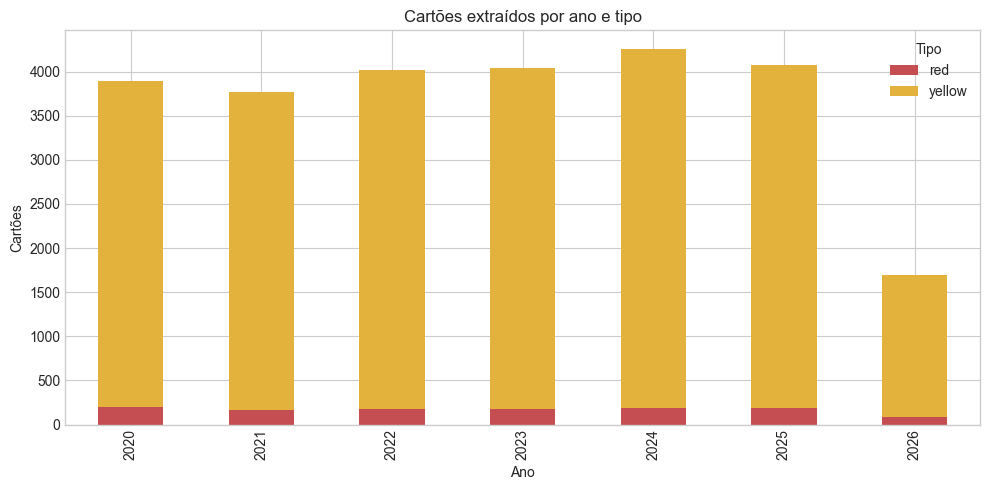

In [99]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = {"yellow": "#E3B23C", "red": "#C44E52"}
card_by_year_type.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=[colors.get(column, "#4C78A8") for column in card_by_year_type.columns],
)
ax.set_title("Cartões extraídos por ano e tipo")
ax.set_xlabel("Ano")
ax.set_ylabel("Cartões")
ax.legend(title="Tipo")
plt.tight_layout()
save_plot(fig, "cards_by_year_type.png")
plt.show()

In [100]:
card_text_counts = (
    cards.groupby(CARD_TEXT_KEY_COLUMN)
    .agg(
        text_for_embedding=(CARD_TEXT_COLUMN, "first"),
        n_events=(CARD_TEXT_COLUMN, "size"),
        n_yellow=("card_type", lambda values: (values == "yellow").sum()),
        n_red=("card_type", lambda values: (values == "red").sum()),
    )
    .reset_index()
    .sort_values("n_events", ascending=False)
    .reset_index(drop=True)
)

card_texts = card_text_counts["text_for_embedding"].tolist()
card_text_counts.head(25)

,card_reason_text_key,text_for_embedding,n_events,n_yellow,n_red
0,por calcar seu adversario de maneira temeraria na disputa de bola,Por calçar seu adversário de maneira temerária na disputa de bola.,500,500,0
1,por cometer uma falta tatica impedindo um ataque promissor,"Por cometer uma falta tática, impedindo um ataque promissor.",410,410,0
2,por retardar o reinicio de jogo,Por retardar o reinicio de jogo,333,333,0
3,cometer uma falta tatica para impedir um ataque promissor,Cometer uma falta tática para impedir um ataque promissor.,285,284,1
4,por cometer uma falta tatica para impedir um ataque promissor,Por cometer uma falta tática para impedir um ataque promissor.,248,247,1
5,por calcar seu adversario de maneira temeraria na disputa da bola,"Por calçar seu adversário de maneira temerária, na disputa da bola",236,236,0
6,por calcar seu adversario de forma temeraria na disputa de bola,Por calçar seu adversário de forma temerária na disputa de bola.,228,228,0
7,dar uma entrada contra um adversario de maneira temeraria na disputa da bola,Dar uma entrada contra um adversário de maneira temerária na disputa da bola.,224,223,1
8,por reclamar contra as decisoes da arbitragem,Por reclamar contra as decisões da arbitragem.,202,202,0
9,por impedir um ataque promissor,Por impedir um ataque promissor.,202,202,0


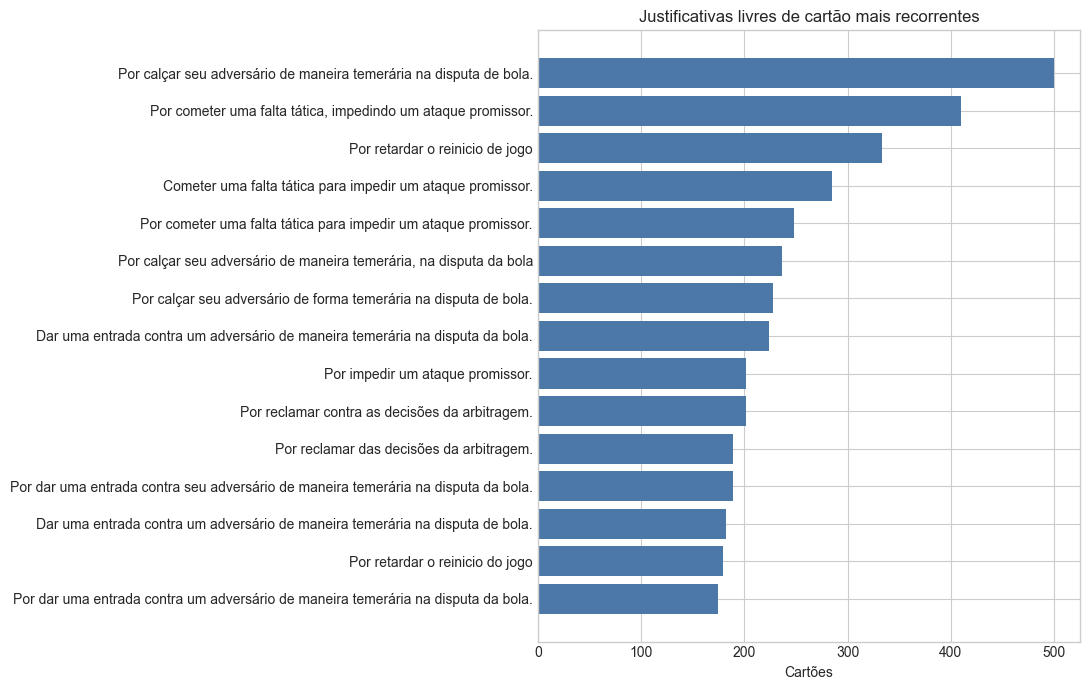

In [101]:
plot_top_texts = card_text_counts.head(TOP_N_CARD_TEXTS).sort_values("n_events")
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(plot_top_texts["text_for_embedding"], plot_top_texts["n_events"], color="#4C78A8")
ax.set_title("Justificativas livres de cartão mais recorrentes")
ax.set_xlabel("Cartões")
ax.set_ylabel("")
plt.tight_layout()
save_plot(fig, "top_card_reason_texts.png")
plt.show()

## **5. Funções Auxiliares**

- `make_topic_model` — cria BERTopic com `embedding_model=None` para usar embeddings pré-calculados; UMAP com `n_components=5`, `metric="cosine"` e `min_dist=0.0` conforme recomendação do BERTopic.
- `load_embedding_model` — carrega `SentenceTransformer` com fallback para transformer puro + mean pooling.
- `silhouette_no_outliers` — exclui label -1 antes do Silhouette Score; incluir outliers como pseudo-classe inflaria artificialmente a métrica.
- `build_topic_summary` — agrega contagens de eventos e termos top por cluster.
- `top_examples_by_topic` — exemplos representativos por tópico, ordenados por frequência.
- `print_cluster_inspection` — formata clusters para inspeção antes da rotulagem semântica.

In [102]:
PORTUGUESE_STOPWORDS = {
    "a", "ao", "aos", "as", "com", "como", "da", "das", "de", "do", "dos", "e", "em", "na", "nas",
    "no", "nos", "o", "os", "ou", "para", "por", "que", "se", "sem", "um", "uma", "uns", "umas",
    "apos", "ate", "contra", "durante", "forma", "maneira", "motivo", "pela", "pelo", "pelas", "pelos",
    "num", "numa", "ter", "tendo", "dado", "haver", "havendo", "advertido", "advertida", "advertir",
    "adversario", "adversaria", "atleta", "jogador", "jogadora", "sr", "sra", "numero", "n", "equipe",
    "bola", "campo", "disputa", "jogada", "jogo", "partida", "seu", "sua", "seus", "suas", "foi", "foram",
    "acrescimo", "acrescimos", "devido", "inicio", "reinicio", "tempo", "minuto", "minutos", "jogadores",
}

def make_topic_model(min_topic_size: int, n_neighbors: int = 15) -> BERTopic:
    vectorizer_model = CountVectorizer(
        stop_words=list(PORTUGUESE_STOPWORDS),
        ngram_range=BERTOPIC_NGRAM_RANGE,
        min_df=2,
    )
    umap_model = umap.UMAP(n_components=5, n_neighbors=n_neighbors, min_dist=0.0, metric="cosine", random_state=RANDOM_STATE)
    return BERTopic(
        language="multilingual",
        embedding_model=None,
        umap_model=umap_model,
        vectorizer_model=vectorizer_model,
        min_topic_size=min_topic_size,
        calculate_probabilities=False,
        verbose=False,
    )

def silhouette_no_outliers(embeddings: np.ndarray, labels, sample_size: int = 3000) -> float:
    mask = np.array(labels) != -1
    if mask.sum() < 2:
        return float('nan')
    return float(
        silhouette_score(
            embeddings[mask], np.array(labels)[mask],
            sample_size=min(sample_size, int(mask.sum())),
            random_state=RANDOM_STATE,
        )
    )

def topic_words(topic_model: BERTopic, topic_id: int, top_n: int = 8) -> str:
    if topic_id == -1:
        return "outliers"
    words = topic_model.get_topic(topic_id) or []
    return ", ".join(word for word, _ in words[:top_n])

def build_topic_summary(topic_model: BERTopic, text_counts: pd.DataFrame, topic_col: str) -> pd.DataFrame:
    topic_info = topic_model.get_topic_info().rename(columns={"Topic": topic_col})
    event_counts = (
        text_counts.groupby(topic_col)
        .agg(
            n_unique_texts=("text_for_embedding", "size"),
            n_events=("n_events", "sum"),
        )
        .reset_index()
    )
    summary = topic_info.merge(event_counts, on=topic_col, how="left")
    summary["top_terms"] = summary[topic_col].map(lambda topic_id: topic_words(topic_model, int(topic_id)))
    return summary.sort_values("n_events", ascending=False).reset_index(drop=True)

def top_examples_by_topic(text_counts: pd.DataFrame, topic_col: str, top_n: int = 5) -> pd.DataFrame:
    columns = [topic_col, "n_events", "text_for_embedding"]
    return (
        text_counts.sort_values([topic_col, "n_events"], ascending=[True, False])
        .groupby(topic_col)
        .head(top_n)
        [columns]
        .reset_index(drop=True)
    )


def load_embedding_model(model_name_or_path) -> SentenceTransformer:
    path = str(model_name_or_path)
    try:
        model = SentenceTransformer(path)
        print(f"[OK] SentenceTransformer: {path}")
        return model
    except Exception:
        word_model = st_models.Transformer(path, max_seq_length=256)
        pooling = st_models.Pooling(
            word_model.get_word_embedding_dimension(),
            pooling_mode_mean_tokens=True,
        )
        model = SentenceTransformer(modules=[word_model, pooling])
        print(f"[OK] Transformer + mean pooling: {path}")
        return model

def model_dir_ready(path: Path) -> bool:
    return (path / "modules.json").exists()

def print_cluster_inspection(
    topic_model: BERTopic,
    text_counts: pd.DataFrame,
    topic_col: str,
    top_n_examples: int = 3,
) -> None:
    summary = build_topic_summary(topic_model, text_counts, topic_col)
    examples_df = top_examples_by_topic(text_counts, topic_col, top_n=top_n_examples)

    print(f"{'ID':>4}  {'Eventos':>8}  Top terms")
    print("-" * 110)
    for _, row in summary.iterrows():
        topic_id = int(row[topic_col])
        n_events = int(row.get("n_events", 0))
        terms = str(row["top_terms"])
        suffix = "  [outliers HDBSCAN]" if topic_id == -1 else ""
        print(f"\n{topic_id:>4}  {n_events:>8,}  {terms}{suffix}")
        examples = examples_df[examples_df[topic_col].eq(topic_id)]["text_for_embedding"].tolist()
        for example in examples:
            print(f"              > {str(example)[:108]}")

## **6. Pipeline NLP — Motivos de Cartão**

Arquitetura de duas passagens: o modelo base produz clusters exploratórios que geram os pares de treino para o fine-tuning; o modelo fine-tunado produz os clusters finais usados na rotulagem semântica.

### **6.1 Embeddings Base**

`paraphrase-multilingual-mpnet-base-v2` (768 dim) aplicado ao conjunto de textos únicos de justificativas. Trabalhar sobre textos únicos — e não sobre todas as ocorrências — reduz o custo computacional do UMAP+HDBSCAN e elimina o viés de duplicatas nos embeddings de cluster.

In [103]:
base_model = load_embedding_model(MODEL_NAME)

base_card_embeddings = base_model.encode(
    [ENCODE_PREFIX_PASSAGE + t for t in card_texts],
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
base_card_embeddings = np.asarray(base_card_embeddings)
print(f"Embeddings base: {base_card_embeddings.shape}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6600.76it/s]


[OK] SentenceTransformer: sentence-transformers/paraphrase-multilingual-mpnet-base-v2


Batches: 100%|██████████| 109/109 [00:10<00:00,  9.95it/s]

Embeddings base: (6940, 768)


### **6.2 Seleção de Hiperparâmetros UMAP e HDBSCAN**

Os dois parâmetros com maior impacto na qualidade dos clusters são `n_neighbors` (UMAP) e `min_topic_size` (HDBSCAN), conforme documentado por Grootendorst (2022):

- **`n_neighbors`** — equilíbrio entre estrutura local e global na projeção UMAP. Valores menores criam fronteiras mais nítidas; valores maiores capturam estrutura global.
- **`min_topic_size`** — threshold de densidade do HDBSCAN; determina o número de clusters e a taxa de outliers.

`min_dist=0.0` é fixado conforme recomendação explícita do BERTopic para maximizar a densidade dos clusters. O Silhouette Score (excluindo outliers HDBSCAN) é a métrica de seleção — maior score indica clusters mais coesos no espaço original de 768 dimensões. Os resultados do grid search são salvos em CSV e reutilizados em execuções subsequentes.

Grid search base carregado do cache (grid_search_results_base.csv)

Melhores parâmetros (base): n_neighbors=15, min_topic_size=25
Silhouette: 0.1448 | clusters: 80 | outliers: 1027


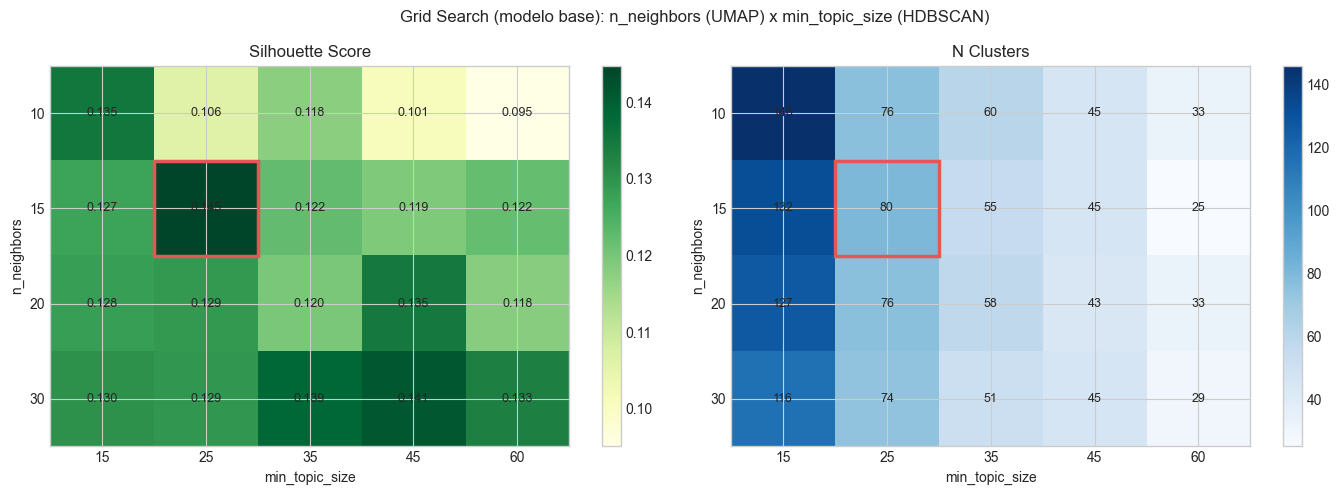

,n_neighbors,min_topic_size,n_clusters,n_outliers,outlier_pct,silhouette
0,10,15,146,929,0.134,0.135121
1,10,25,76,712,0.103,0.106071
2,10,35,60,802,0.116,0.117737
3,10,45,45,797,0.115,0.100758
4,10,60,33,1095,0.158,0.095101
5,15,15,132,846,0.122,0.127238
6,15,25,80,1027,0.148,0.144784
7,15,35,55,901,0.130,0.122352
8,15,45,45,973,0.140,0.119092
9,15,60,25,486,0.070,0.121884


In [104]:
GRID_SEARCH_BASE_PATH = OUTPUT_DIR / "grid_search_results_base.csv"
RERUN_GRID_SEARCH = False

N_NEIGHBORS_RANGE = [10, 15, 20, 30]
MIN_TOPIC_SIZE_RANGE = [15, 25, 35, 45, 60]

def _ranges_match(df: pd.DataFrame) -> bool:
    return (
        sorted(df["n_neighbors"].unique().tolist()) == sorted(N_NEIGHBORS_RANGE)
        and sorted(df["min_topic_size"].unique().tolist()) == sorted(MIN_TOPIC_SIZE_RANGE)
    )

def _run_grid_search(embeddings: np.ndarray, label: str) -> pd.DataFrame:
    combos = [(n, m) for n in N_NEIGHBORS_RANGE for m in MIN_TOPIC_SIZE_RANGE]
    results = []
    for i, (n_nb, mts) in enumerate(combos):
        _m = make_topic_model(mts, n_neighbors=n_nb)
        _topics, _ = _m.fit_transform(card_texts, embeddings=embeddings)
        _n_clusters = len(set(_topics) - {-1})
        _n_outliers = int((np.array(_topics) == -1).sum())
        _sil = silhouette_no_outliers(embeddings, _topics)
        results.append({"n_neighbors": n_nb, "min_topic_size": mts,
                         "n_clusters": _n_clusters, "n_outliers": _n_outliers,
                         "outlier_pct": round(_n_outliers / len(_topics), 3), "silhouette": _sil})
        print(f"  [{i+1:2d}/{len(combos)}] n_neighbors={n_nb:2d} | min_topic_size={mts:2d} | clusters={_n_clusters:3d} | outliers={_n_outliers:4d} | silhouette={float(_sil):.4f}")
    return pd.DataFrame(results)

if not RERUN_GRID_SEARCH and GRID_SEARCH_BASE_PATH.exists():
    grid_df = pd.read_csv(GRID_SEARCH_BASE_PATH)
    if not _ranges_match(grid_df):
        print("Ranges alterados — re-executando grid search base...")
        RERUN_GRID_SEARCH = True
    else:
        print(f"Grid search base carregado do cache ({GRID_SEARCH_BASE_PATH.name})")

if RERUN_GRID_SEARCH or not GRID_SEARCH_BASE_PATH.exists():
    print("Grid search: n_neighbors x min_topic_size (modelo base)...")
    grid_df = _run_grid_search(base_card_embeddings, "base")
    grid_df.to_csv(GRID_SEARCH_BASE_PATH, index=False)
    print(f"Salvo em {GRID_SEARCH_BASE_PATH}")

valid_grid = grid_df.dropna(subset=["silhouette"])
best_row = valid_grid.loc[valid_grid["silhouette"].idxmax()]
best_n_neighbors = int(best_row["n_neighbors"])
best_min_topic_size = int(best_row["min_topic_size"])
print(f"\nMelhores parâmetros (base): n_neighbors={best_n_neighbors}, min_topic_size={best_min_topic_size}")
print(f"Silhouette: {best_row['silhouette']:.4f} | clusters: {int(best_row['n_clusters'])} | outliers: {int(best_row['n_outliers'])}")

sil_pivot = grid_df.pivot(index="n_neighbors", columns="min_topic_size", values="silhouette")
nc_pivot  = grid_df.pivot(index="n_neighbors", columns="min_topic_size", values="n_clusters")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, pivot, title, cmap in zip(
    axes, [sil_pivot, nc_pivot], ["Silhouette Score", "N Clusters"], ["YlGn", "Blues"],
):
    im = ax.imshow(pivot.values, aspect="auto", cmap=cmap)
    ax.set_xticks(range(len(MIN_TOPIC_SIZE_RANGE)))
    ax.set_xticklabels(MIN_TOPIC_SIZE_RANGE)
    ax.set_yticks(range(len(N_NEIGHBORS_RANGE)))
    ax.set_yticklabels(N_NEIGHBORS_RANGE)
    ax.set_xlabel("min_topic_size")
    ax.set_ylabel("n_neighbors")
    ax.set_title(title)
    for ii in range(len(N_NEIGHBORS_RANGE)):
        for jj in range(len(MIN_TOPIC_SIZE_RANGE)):
            val = pivot.iloc[ii, jj]
            ax.text(jj, ii, f"{val:.3f}" if title == "Silhouette Score" else str(int(val)), ha="center", va="center", fontsize=9)
    plt.colorbar(im, ax=ax)
    best_i = N_NEIGHBORS_RANGE.index(best_n_neighbors)
    best_j = MIN_TOPIC_SIZE_RANGE.index(best_min_topic_size)
    ax.add_patch(plt.Rectangle((best_j - 0.5, best_i - 0.5), 1, 1, fill=False, edgecolor="#E45756", linewidth=2.5))

plt.suptitle("Grid Search (modelo base): n_neighbors (UMAP) x min_topic_size (HDBSCAN)", fontsize=12)
plt.tight_layout()
save_plot(fig, "umap_param_grid_search_base.png")
plt.show()
grid_df

### **6.3 BERTopic — Passagem 1 (Exploração)**

Clustering com o modelo base. Os tópicos encontrados **não** são os rótulos finais — servem exclusivamente como fonte de pares positivos para o fine-tuning. Textos no mesmo cluster HDBSCAN formam pares semanticamente coerentes; outliers (label -1) são descartados por não pertencerem a nenhum grupo denso.

In [105]:
card_topic_model_pass1 = make_topic_model(best_min_topic_size, n_neighbors=best_n_neighbors)
card_topics_pass1, _ = card_topic_model_pass1.fit_transform(card_texts, embeddings=base_card_embeddings)
card_text_counts["bertopic_topic_pass1"] = card_topics_pass1

n_clusters_pass1 = len(set(card_topics_pass1) - {-1})
n_outliers_pass1 = int((np.array(card_topics_pass1) == -1).sum())
sil_pass1 = silhouette_no_outliers(base_card_embeddings, card_topics_pass1)

pass1_counts = card_text_counts.rename(columns={"bertopic_topic_pass1": "bertopic_topic"})
pass1_summary = build_topic_summary(card_topic_model_pass1, pass1_counts, "bertopic_topic")
pass1_summary = pass1_summary.rename(columns={"bertopic_topic": "bertopic_topic_pass1"})

print(f"Pass 1 — clusters: {n_clusters_pass1} | outliers: {n_outliers_pass1} ({100*n_outliers_pass1/len(card_topics_pass1):.1f}%) | silhouette: {sil_pass1:.4f}")
pass1_summary.head(20)

Pass 1 — clusters: 80 | outliers: 1027 (14.8%) | silhouette: 0.1448


,bertopic_topic_pass1,Count,Name,Representation,Representative_Docs,n_unique_texts,n_events,top_terms
0,-1,1027,-1_arbitragem_reclamar_decisões_decisões arbitragem,"[arbitragem, reclamar, decisões, decisões arbitragem, temerária, palavras, cometer, antidesportiva, cabeça, chutar]","[Por gesticular e reclamar de maneira acintosa contra as decisões da arbitragem., Por reclamar de forma acintosa das decisões da equipe de arbitragem., Por reclamar de maneira acintosa contra as decisões da equipe de...",1027,2569,outliers
1,3,185,3_entrada_dar entrada_entrada temerária adversário_adversário dar entrada,"[entrada, dar entrada, entrada temerária adversário, adversário dar entrada, entrada temerária, dar entrada temerária, dar, adversário dar, temerária adversário dar, entrada adversário temerária]","[Por dar uma entrada temerária em seu adversário da disputa da bola., Por dar uma entrada de maneira temerária no seu adversário na disputa de bola., Por dar uma entrada, de maneira temerária contra o adversário na d...",185,2280,"entrada, dar entrada, entrada temerária adversário, adversário dar entrada, entrada temerária, dar entrada temerária, dar, adversário dar"
2,15,98,15_calçar_calçar adversário_calçar adversário temerária_temerária calçar,"[calçar, calçar adversário, calçar adversário temerária, temerária calçar, temerária calçar adversário, adversário temerária calçar, adversário calçar, adversário calçar adversário, adversário temerária, calçar temer...","[Por calçar adversário de forma temerária na disputa de bola., Por calçar um adversário de maneira temerária na disputa de bola., Por calçar o adversário de forma temerária, na disputa da bola.]",98,2107,"calçar, calçar adversário, calçar adversário temerária, temerária calçar, temerária calçar adversário, adversário temerária calçar, adversário calçar, adversário calçar adversário"
3,6,117,6_promissor cometer_ataque promissor cometer_promissor cometer falta_impedir ataque,"[promissor cometer, ataque promissor cometer, promissor cometer falta, impedir ataque, ataque, promissor, ataque promissor, impedir ataque promissor, impedir, cometer falta]","[Cometer uma falta tática para impedir um ataque promissor., Por cometer uma falta tática para impedir uma ataque promissor., Cometer um a falta tática para impedir um ataque promissor.]",117,1708,"promissor cometer, ataque promissor cometer, promissor cometer falta, impedir ataque, ataque, promissor, ataque promissor, impedir ataque promissor"
4,5,131,5_dar entrada_entrada_dar entrada adversário_entrada adversário,"[dar entrada, entrada, dar entrada adversário, entrada adversário, adversário dar entrada, temerária dar entrada, dar, entrada adversário temerária, dar entrada temerária, adversário dar]","[Dar uma entrada em um adversário de maneira temerária em disputa de bola., Dar uma entrada contra seu adversário de maneira temerária na disputa da bola., Dar uma entrada em seu adversário temerária na disputa da bo...",131,1353,"dar entrada, entrada, dar entrada adversário, entrada adversário, adversário dar entrada, temerária dar entrada, dar, entrada adversário temerária"
5,17,93,17_retardar_reinício_retardar reinício_substituição,"[retardar, reinício, retardar reinício, substituição, lateral retardar, reinício retardar, arremesso lateral retardar, substituição retardar, arremesso lateral, arremesso]","[Por retardar o reinício de jogo em uma substituição., Por retardar o reinício de jogo durante uma substituição, Por retardar o reinício do jogo no momento do arremesso lateral.]",93,904,"retardar, reinício, retardar reinício, substituição, lateral retardar, reinício retardar, arremesso lateral retardar, substituição retardar"
6,16,95,16_arbitragem reclamar_reclamar_decisões arbitragem reclamar_decisão arbitragem reclamar,"[arbitragem reclamar, reclamar, decisões arbitragem reclamar, decisão arbitragem reclamar, arbitragem, decisão arbitragem, decisão, decisões, decisões arbitragem, arbitragem reclamar acintosa]","[Reclamar de forma ac

### **6.4 Fine-Tuning do Sentence Transformer**

`MultipleNegativesRankingLoss` trata cada par `(âncora, positivo)` no batch como positivo; os demais positivos no mesmo batch atuam como negativos implícitos. Esta formulação — usada em dense retrieval (Karpukhin et al., 2020) e contrastive learning de sentenças (Gao et al., 2021 / SimCSE) — é eficiente computacionalmente e adequada para corpus pequeno com vocabulário especializado.

A geração automática de pares a partir dos clusters do BERTopic é uma forma de *self-supervised contrastive learning*: a própria estrutura semântica descoberta na Passagem 1 fornece o sinal de supervisão, sem necessidade de rótulos manuais.

In [106]:
def build_pairs_from_labels(
    text_counts: pd.DataFrame,
    labels,
    max_texts: int = MAX_TEXTS_PER_GROUP_FOR_FINETUNE,
    max_pairs: int = MAX_TEXT_PAIRS_PER_GROUP_FOR_FINETUNE,
    prefix: str = "",
) -> list[dict]:
    df = text_counts.copy()
    df["_label"] = labels
    pairs: list[dict] = []
    for lbl, group in df.groupby("_label"):
        if int(lbl) == -1:
            continue
        texts = (
            group.sort_values("n_events", ascending=False)["text_for_embedding"]
            .dropna().astype(str).str.strip()
            .loc[lambda s: s.ne("")]
            .drop_duplicates()
            .head(max_texts)
            .tolist()
        )
        pairs.extend(
            {"anchor": prefix + a, "positive": prefix + b}
            for a, b in list(combinations(texts, 2))[:max_pairs]
        )
    return pairs

if RUN_FINE_TUNING:
    if USE_FINETUNED_IF_AVAILABLE and model_dir_ready(FINETUNED_MODEL_DIR) and not RETRAIN_FINETUNED_MODEL:
        print(f"Modelo fine-tunado encontrado em {FINETUNED_MODEL_DIR}. Carregando.")
        embedding_model = load_embedding_model(FINETUNED_MODEL_DIR)
    else:
        import datasets as hf_datasets
        from sentence_transformers import SentenceTransformerTrainer, SentenceTransformerTrainingArguments
        from sentence_transformers.losses import MultipleNegativesRankingLoss
        from sentence_transformers.training_args import BatchSamplers
        import sentence_transformers.base.trainer as st_base_trainer

        if not hasattr(st_base_trainer, "IterableDataset"):
            from torch.utils.data import IterableDataset as TorchIterableDataset
            st_base_trainer.IterableDataset = TorchIterableDataset

        if FINETUNED_MODEL_DIR.exists() and RETRAIN_FINETUNED_MODEL:
            shutil.rmtree(FINETUNED_MODEL_DIR)

        positive_pairs = build_pairs_from_labels(
            card_text_counts, card_topics_pass1, prefix=ENCODE_PREFIX_PASSAGE
        )
        n_outlier_texts = int((np.array(card_topics_pass1) == -1).sum())
        if not positive_pairs:
            raise ValueError("Nenhum par positivo gerado pelo BERTopic Pass 1.")
        print(f"Pares positivos gerados (BERTopic Pass 1): {len(positive_pairs):,}")
        print(f"Textos outlier excluídos: {n_outlier_texts}")

        train_dataset = hf_datasets.Dataset.from_list(positive_pairs)
        ft_model = load_embedding_model(MODEL_NAME)
        train_loss = MultipleNegativesRankingLoss(ft_model)
        training_args = SentenceTransformerTrainingArguments(
            output_dir=str(FINETUNED_MODEL_DIR / "checkpoints"),
            num_train_epochs=FINETUNE_EPOCHS,
            per_device_train_batch_size=FINETUNE_BATCH_SIZE,
            learning_rate=2e-5,
            warmup_ratio=0.1,
            fp16=False,
            use_cpu=True,
            batch_sampler=BatchSamplers.NO_DUPLICATES,
            save_strategy="no",
            logging_steps=50,
        )
        trainer = SentenceTransformerTrainer(
            model=ft_model,
            args=training_args,
            train_dataset=train_dataset,
            loss=train_loss,
        )
        trainer.train()
        ft_model.save(str(FINETUNED_MODEL_DIR))
        embedding_model = ft_model
        print(f"Modelo salvo em: {FINETUNED_MODEL_DIR}")
else:
    embedding_model = base_model
    print("Fine-tuning desabilitado. Usando modelo base.")

print(f"Dimensão dos embeddings: {embedding_model.get_sentence_embedding_dimension()}")


Modelo fine-tunado encontrado em /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/models/football_card_reason_mpnet_two_pass. Carregando.


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7378.53it/s]


[OK] SentenceTransformer: /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/models/football_card_reason_mpnet_two_pass
Dimensão dos embeddings: 768


### **6.5 BERTopic — Passagem 2 (Clusters Finais)**

O modelo fine-tunado gera embeddings com maior separabilidade intra-domínio. Um segundo grid search é executado sobre os embeddings fine-tunados — os hiperparâmetros ótimos podem diferir dos da Passagem 1, pois a geometria do espaço de embeddings muda após o fine-tuning.

In [107]:
card_embeddings = embedding_model.encode(
    [ENCODE_PREFIX_PASSAGE + t for t in card_texts],
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
card_embeddings = np.asarray(card_embeddings)
print(f"Embeddings de cartões: {card_embeddings.shape}")

Batches: 100%|██████████| 109/109 [00:12<00:00,  8.98it/s]

Embeddings de cartões: (6940, 768)


In [108]:
GRID_SEARCH_FT_PATH = OUTPUT_DIR / "grid_search_results_ft.csv"
RERUN_GRID_SEARCH_FT = RETRAIN_FINETUNED_MODEL

if not RERUN_GRID_SEARCH_FT and GRID_SEARCH_FT_PATH.exists():
    grid_ft_df = pd.read_csv(GRID_SEARCH_FT_PATH)
    if not _ranges_match(grid_ft_df):
        print("Ranges alterados — re-executando grid search FT...")
        RERUN_GRID_SEARCH_FT = True
    else:
        print(f"Grid search FT carregado do cache ({GRID_SEARCH_FT_PATH.name})")

if RERUN_GRID_SEARCH_FT or not GRID_SEARCH_FT_PATH.exists():
    print("Grid search: n_neighbors x min_topic_size (modelo fine-tunado)...")
    grid_ft_df = _run_grid_search(card_embeddings, "ft")
    grid_ft_df.to_csv(GRID_SEARCH_FT_PATH, index=False)
    print(f"Salvo em {GRID_SEARCH_FT_PATH}")

valid_ft = grid_ft_df.dropna(subset=["silhouette"])
best_row_ft = valid_ft.loc[valid_ft["silhouette"].idxmax()]
best_n_neighbors_ft = int(best_row_ft["n_neighbors"])
best_min_topic_size_ft = int(best_row_ft["min_topic_size"])
print(f"\nMelhores parâmetros (fine-tunado): n_neighbors={best_n_neighbors_ft}, min_topic_size={best_min_topic_size_ft}")
print(f"Silhouette: {best_row_ft['silhouette']:.4f} | clusters: {int(best_row_ft['n_clusters'])} | outliers: {int(best_row_ft['n_outliers'])}")

Grid search FT carregado do cache (grid_search_results_ft.csv)

Melhores parâmetros (fine-tunado): n_neighbors=15, min_topic_size=35
Silhouette: 0.4530 | clusters: 77 | outliers: 430


In [109]:
card_topic_model = make_topic_model(best_min_topic_size_ft, n_neighbors=best_n_neighbors_ft)
card_topics, _ = card_topic_model.fit_transform(card_texts, embeddings=card_embeddings)
card_text_counts["bertopic_topic"] = card_topics

n_clusters_pass2 = len(set(card_topics) - {-1})
n_outliers_pass2 = int((np.array(card_topics) == -1).sum())
sil_pass2 = silhouette_no_outliers(card_embeddings, card_topics)

card_topic_summary = build_topic_summary(card_topic_model, card_text_counts, "bertopic_topic")
print(f"Pass 2 — clusters: {n_clusters_pass2} | outliers: {n_outliers_pass2} ({100*n_outliers_pass2/len(card_topics):.1f}%) | silhouette: {sil_pass2:.4f}")
card_topic_summary.head(20)

Pass 2 — clusters: 77 | outliers: 430 (6.2%) | silhouette: 0.4530


,bertopic_topic,Count,Name,Representation,Representative_Docs,n_unique_texts,n_events,top_terms
0,2,150,2_entrada_dar entrada_entrada temerária adversário_adversário dar entrada,"[entrada, dar entrada, entrada temerária adversário, adversário dar entrada, entrada temerária, dar entrada temerária, entrada adversário temerária, temerária adversário dar, entrada adversário, temerária dar entrada]","[Por dar uma entrada de maneira temerária no seu adversário na disputa da bola, Por dar uma entrada temerária em seu adversário numa disputa de bola., Por dar uma entrada de maneira temerária contra seu adversário na...",150,2223,"entrada, dar entrada, entrada temerária adversário, adversário dar entrada, entrada temerária, dar entrada temerária, entrada adversário temerária, temerária adversário dar"
1,20,98,20_calçar_calçar adversário_calçar adversário temerária_temerária calçar,"[calçar, calçar adversário, calçar adversário temerária, temerária calçar, temerária calçar adversário, adversário temerária calçar, adversário calçar, adversário calçar adversário, adversário temerária, calçar temer...","[Por calçar seu adversário de forma temerária em disputa de bola., Por calçar o seu adversário de forma temerária em disputa de bola, Por calçar o seu adversário de forma temerária na disputa da bola.]",98,2104,"calçar, calçar adversário, calçar adversário temerária, temerária calçar, temerária calçar adversário, adversário temerária calçar, adversário calçar, adversário calçar adversário"
2,9,121,9_promissor cometer_ataque promissor cometer_promissor cometer falta_ataque,"[promissor cometer, ataque promissor cometer, promissor cometer falta, ataque, promissor, impedir ataque, ataque promissor, impedir ataque promissor, impedir, cometer falta]","[Por cometer um falta tática para impedir um ataque promissor., Advertido por cometer falta tática para impedir ataque promissor., Por cometer uma falta tática para impedir uma ataque promissor.]",121,1717,"promissor cometer, ataque promissor cometer, promissor cometer falta, ataque, promissor, impedir ataque, ataque promissor, impedir ataque promissor"
3,7,128,7_dar entrada_entrada_entrada adversário_dar entrada adversário,"[dar entrada, entrada, entrada adversário, dar entrada adversário, temerária dar entrada, adversário dar entrada, dar, entrada adversário temerária, temerária dar, adversário dar]","[Dar uma entrada contra adversário de maneira temerária na disputa de bola., Dar uma entrada contra seu adversário de maneira temerária durante uma disputa pela bola., Dar uma entrada contra o seu adversário, de form...",128,1350,"dar entrada, entrada, entrada adversário, dar entrada adversário, temerária dar entrada, adversário dar entrada, dar, entrada adversário temerária"
4,-1,430,-1_simular_subir_enganar_falta,"[simular, subir, enganar, falta, sofrido, tentar, gol subir, tentar enganar, sofrido falta, retardar]","[Por simular ter sofrido uma falta para enganar o arbitro., Por tentar enganar o árbitro simulando uma falta dentro da área penal., Tentar enganar o árbitro fingindo ter sofrido uma falta. (simulação)]",430,1195,outliers
5,5,131,5_arbitragem reclamar_reclamar_decisões arbitragem reclamar_arbitragem,"[arbitragem reclamar, reclamar, decisões arbitragem reclamar, arbitragem, decisão arbitragem reclamar, decisão arbitragem, decisão, decisões arbitragem, decisões, arbitragem reclamar acintosa]","[Por reclamar de forma acintosa contra a decisão da arbitragem., Por reclamar contra as decisções da arbitragem., Por reclamar acinstosamente contra as decisões da arbitragem.]",131,920,"arbitragem reclamar, reclamar, decisões arbitragem reclamar, arbitragem, decisão arbitragem reclamar, decisão arbitragem, decisão, decisões arbitragem"
6,40,77,40_retardar_lateral retardar_lateral_arremesso lateral,"[retardar, lateral retardar, lateral, arremesso lateral, arremesso, reinício, arremesso lateral retardar, reinício retardar, retardar retardar, retardar reinício]","[Por retardar reinicio de jogo na cobra

In [110]:
card_topic_examples = top_examples_by_topic(card_text_counts, "bertopic_topic", top_n=5)
card_topic_examples.head(30)

,bertopic_topic,n_events,text_for_embedding
0,-1,107,Por calçar seu adversário de maneira temerária
1,-1,101,Por calçar seu adversário de forma temerária.
2,-1,48,Por conduta antidesportiva.
3,-1,37,Por atitude antidesportiva
4,-1,32,Por calçar o seu adversário de maneira temerária.
5,0,2,"Por desferir dois tapas, um no braço e outro nas costas do seu adversario de nº 03, sr. rodrigo caio coquette russo, fora da disputa da bola. o atleta atingido continuou no jogo normalmente. o atleta expulso deixou o..."
6,0,2,"Por dar uma entrada em seu adversário de n° 15, sr. victor leandro cuesta, de forma temerária, na disputa da bola (segundo cartão amarelo)."
7,0,2,"Por desferir uma cotovelada atingindo o rosto do seu adversário senhor angelo giovani araos llanos, número 21, fora da disputa da bola com uso de força excessiva. o atleta atingido necessitou de atendimento médico e ..."
8,0,2,"Por dar uma entrada temerária contra seu adversário na disputa da bola, recebeu o segundo cartão amarelo."
9,0,2,"Por chutar a perna de seu adversário, atingindo a pantorrilha do mesmo com uso de força excessiva, quando a bola estava fora de jogo, informo que o atleta atingido continuou na partida e o atleta expulso saiu sem ami..."


### **6.6 Ablação: Modelo Base vs. Fine-Tunado**

Comparação direta entre Pass 1 (modelo base) e Pass 2 (modelo fine-tunado) usando os hiperparâmetros ótimos de cada passagem. As métricas — número de clusters, taxa de outliers e Silhouette Score — quantificam o ganho do fine-tuning na separabilidade semântica dos embeddings.

Ganho de silhouette: +212.9%


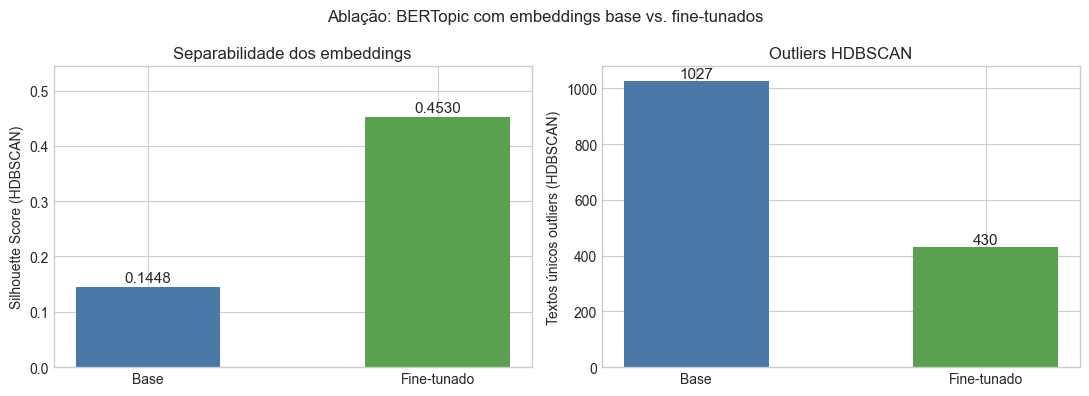

,Passagem,n_neighbors,min_topic_size,N Clusters,Outliers,Outlier %,Silhouette Score
0,Pass 1 — Modelo base,15,25,80,1027,14.8%,0.1448
1,Pass 2 — Fine-tunado,15,35,77,430,6.2%,0.4530


In [111]:
outlier_pct_pass1 = 100 * n_outliers_pass1 / len(card_topics_pass1)
outlier_pct_pass2 = 100 * n_outliers_pass2 / len(card_topics)
sil_gain = (sil_pass2 - sil_pass1) / sil_pass1 * 100

ablation_table = pd.DataFrame({
    "Passagem": ["Pass 1 — Modelo base", "Pass 2 — Fine-tunado"],
    "n_neighbors": [best_n_neighbors, best_n_neighbors_ft],
    "min_topic_size": [best_min_topic_size, best_min_topic_size_ft],
    "N Clusters": [n_clusters_pass1, n_clusters_pass2],
    "Outliers": [n_outliers_pass1, n_outliers_pass2],
    "Outlier %": [f"{outlier_pct_pass1:.1f}%", f"{outlier_pct_pass2:.1f}%"],
    "Silhouette Score": [round(sil_pass1, 4), round(sil_pass2, 4)],
})
print(f"Ganho de silhouette: +{sil_gain:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
labels = ["Base", "Fine-tunado"]
colors = ["#4C78A8", "#59A14F"]

axes[0].bar(labels, [sil_pass1, sil_pass2], color=colors, width=0.5)
for ax_bar, val in zip(axes[0].patches, [sil_pass1, sil_pass2]):
    axes[0].text(ax_bar.get_x() + ax_bar.get_width() / 2, val + 0.003, f"{val:.4f}", ha="center", va="bottom", fontsize=11)
axes[0].set_ylabel("Silhouette Score (HDBSCAN)")
axes[0].set_title("Separabilidade dos embeddings")
axes[0].set_ylim(0, max(sil_pass1, sil_pass2) * 1.2)

axes[1].bar(labels, [n_outliers_pass1, n_outliers_pass2], color=colors, width=0.5)
for ax_bar, val in zip(axes[1].patches, [n_outliers_pass1, n_outliers_pass2]):
    axes[1].text(ax_bar.get_x() + ax_bar.get_width() / 2, val + 0.5, str(val), ha="center", va="bottom", fontsize=11)
axes[1].set_ylabel("Textos únicos outliers (HDBSCAN)")
axes[1].set_title("Outliers HDBSCAN")

plt.suptitle("Ablação: BERTopic com embeddings base vs. fine-tunados", fontsize=12)
plt.tight_layout()
save_plot(fig, "ablation_silhouette.png")
plt.show()
ablation_table

## **7. Rotulagem Semântica dos Clusters**

A rotulagem usa protótipos manuais com *prototype matching* por similaridade de cosseno — classificação semi-supervisionada com *seed embeddings*, análoga às Prototypical Networks (Snell et al., 2017) e ao modo guiado do BERTopic.

Em vez de centroides de grupo (média dos protótipos), cada vetor é comparado diretamente à **matriz de todos os protótipos individuais**; a similaridade usada é o **máximo** sobre todos os protótipos do grupo. Isso elimina a diluição de centroide causada por protótipos semanticamente diversos.

O processo ocorre em três passagens:

1. **Centroide de cluster → max(protótipos)** com `SIMILARITY_THRESHOLD`: cada cluster BERTopic recebe o grupo com protótipo individualmente mais próximo. Clusters sem match suficiente ficam em `Outros`. Esta passagem é eficiente mas sujeita a erro em clusters mistos — o centroide médio pode não representar bem os textos individuais.

2. **Texto individual → max(protótipos)** com `OUTLIER_THRESHOLD`: textos em `Outros` (outliers HDBSCAN e clusters não atribuídos) são comparados individualmente, com limiar mais permissivo.

3. **Re-avaliação por confiança individual** com `OVERRIDE_MARGIN`: todos os textos já atribuídos são reavaliados com seu próprio embedding. Se o grupo mais similar individualmente for *diferente* do grupo atual e a margem de similaridade superar `OVERRIDE_MARGIN`, o texto é reatribuído. Esta passagem corrige erros da passagem 1 causados por centroides de clusters mistos.

In [112]:
print_cluster_inspection(card_topic_model, card_text_counts, "bertopic_topic")

  ID   Eventos  Top terms
--------------------------------------------------------------------------------------------------------------

   2     2,223  entrada, dar entrada, entrada temerária adversário, adversário dar entrada, entrada temerária, dar entrada temerária, entrada adversário temerária, temerária adversário dar
              > Por dar uma entrada contra seu adversário de maneira temerária na disputa da bola.
              > Por dar uma entrada contra um adversário de maneira temerária na disputa da bola.
              > Por dar uma entrada em seu adversário de maneira temerária na disputa de bola.

  20     2,104  calçar, calçar adversário, calçar adversário temerária, temerária calçar, temerária calçar adversário, adversário temerária calçar, adversário calçar, adversário calçar adversário
              > Por calçar seu adversário de maneira temerária na disputa de bola.
              > Por calçar seu adversário de maneira temerária, na disputa da bola
              > Po

In [113]:
GROUP_PROTOTYPES: dict[str, list[str]] = {
    "Ação temerária": [
        "calçar adversário de maneira temerária na disputa de bola",
        "dar entrada temerária no adversário",
        "golpear adversário de maneira temerária na disputa de bola",
        "rasteira temerária contra adversário na disputa de bola",
        "entrada contra adversário de forma temerária",
        "dar um calço temerário na disputa de bola",
        "golpear adversário com o braço de forma temerária na disputa de bola",
        "atingir adversário com o braço de maneira temerária na disputa de bola",
        "Por dar um calço em um adversário de maneira temerária na disputa de bola",
        "Por dar um calço no adversário de forma temerária na disputa da bola",
        "Por atingir seu adversário de maneira temerária na disputa de bola",
        "Por atingir a perna de seu adversário de forma temerária na disputa da bola",
        "Golpear um adversário de maneira temerária na disputa da bola",
        "Golpear seu adversário com o braço de forma temerária na disputa de bola",
        "Por dar um calço em seu adversário de maneira temerária na disputa da bola",
        "Dar um calço em seu adversário de maneira temerária na disputa de bola",
        "Por atingir com o braço de forma temerária seu adversário na disputa de bola",
        "Em lance de disputa de bola, ter atingido seu adversário com uma entrada temerária",
        "Por golpear seu adversário de maneira temerária na disputa de bola",
        "Por golpear seu adversário de maneira temerária na disputa da bola",
        "Por golpear um adversário de maneira temerária na disputa de bola",
        "calçar adversário de maneira temerária",
        "calçar adversário de forma temerária",
        "dar uma entrada temerária no adversário",
        "entrada de maneira temerária no adversário",
        "dar um calço temerário no adversário",
        "Por calçar seu adversário de maneira temerária",
        "Por calçar seu adversário de forma temerária",
        "dar um pontapé de maneira temerária na disputa da bola",
        "dar um chute de maneira temerária na disputa da bola",
        "chutar adversário de maneira temerária na disputa de bola",
    ],
    "Ataque promissor / falta tática": [
        "cometer falta tática impedindo ataque promissor",
        "impedir oportunidade clara de gol",
        "segurar adversário impedindo ataque promissor",
        "falta tática para impedir ataque promissor",
        "mão na bola impedindo ataque promissor",
        "segurar adversário na disputa de bola impedindo ataque promissor",
        "agarrar adversário interrompendo ataque promissor",
        "impedir oportunidade clara de gol com uso das mãos fora da área",
        "Por atingir a perna de seu adversário na disputa da bola, impedindo um ataque promissor",
        "impedir uma clara e manifesta oportunidade de gol",
        "segurar adversário por motivo tático",
        "segurar adversário por motivo tático derrubando ao solo",
        "fazer uma carga no adversário impedindo um ataque promissor",
        "cometer uma carga no adversário interrompendo um ataque promissor",
    ],
    "Protesto contra arbitragem": [
        "reclamar das decisões da arbitragem",
        "desaprovar com palavras e gestos as decisões da arbitragem",
        "protestar de forma acintosa contra as decisões da arbitragem",
        "reclamar contra as marcações da arbitragem",
        "reclamar das decisões da arbitragem de maneira acintosa do banco de reservas",
        "se levantar do banco de reservas e protestar de maneira acintosa",
        "conduta antidesportiva ao protestar de forma acintosa contra as decisões da arbitragem",
        "conduta antidesportiva ao reclamar de forma acintosa contra as decisões da arbitragem",
        "reclamar das decisões da arbitragem chutando a bola ao solo em protesto",
        "jogar a bola ao solo protestando contra as decisões da arbitragem",
        "arremessar a bola em protesto contra a marcação da arbitragem",
        "desaprovar a decisão da arbitragem chutando a bola para fora do campo",
        "reclamação por palavras",
        "reclamar de forma acintosa",
        "reclamar por palavras e gestos",
    ],
    "Conduta antidesportiva/regras": [
        "infringir persistentemente as regras do jogo",
        "por sua equipe infringir persistentemente as regras do jogo",
        "simular falta para enganar o árbitro",
        "simular ter sofrido uma falta",
        "fazer marcas não autorizadas no campo de jogo",
        "abandonar o campo de jogo sem a permissão do árbitro",
    ],
    "Agarrar / desrespeito ao jogo": [
        "segurar seu adversário mostrando desrespeito ao jogo",
        "agarrar o adversário de forma acintosa mostrando desrespeito ao jogo",
        "puxar adversário pela camisa mostrando desrespeito ao jogo",
        "segurar adversário de maneira acintosa demonstrando desrespeito ao jogo",
        "atuar de maneira a mostrar desrespeito ao jogo agarrando adversário",
        "mostrar desrespeito ao jogo segurando adversário",
        "agarrar seu adversário de maneira a mostrar desrespeito ao jogo",
        "atuar de maneira a mostrar desrespeito ao jogo",
        "Por atuar de maneira a mostrar desrespeito ao jogo",
        "desrespeito ao jogo",
        "segurar adversário de forma acintosa",
        "Por segurar seu adversário de forma acintosa",
        "agarrar adversário acintosamente",
        "segurar adversário de maneira acintosa",
    ],
    "Retardar/reiniciar jogo": [
        "retardar o reinício de jogo",
        "chutar bola para longe com jogo paralisado",
        "retardar arremesso lateral ou tiro livre",
        "retardar saída de campo durante substituição",
        "demorar para reiniciar o jogo",
        "chutar a bola para longe com o jogo paralisado",
        "chutar a bola para longe depois de o árbitro ter paralisado o jogo",
        "chutar a bola para longe após a marcação de uma falta",
        "retardar o reinício do jogo chutando a bola após o apito do árbitro",
    ],
    "Comemoração/entrada em campo": [
        "tirar camisa na comemoração de gol",
        "entrar em campo para comemorar gol sem permissão do árbitro",
        "subir no alambrado para comemorar um gol",
        "subir na escada em volta do campo para comemorar um gol",
        "subir na arquibancada para comemorar um gol",
        "entrar no campo de jogo sem a permissão da arbitragem",
        "entrar no campo de jogo sem a permissão do árbitro",
        "retornar ao campo de jogo sem autorização",
        "invadir o campo de jogo sem autorização",
    ],
    "Força excessiva / jogo brusco grave": [
        "dar soco no adversário",
        "dar soco no rosto do adversário",
        "cotovelada no rosto do adversário",
        "atingir adversário no rosto com o cotovelo",
        "golpear adversário no rosto com o punho",
        "golpear adversário com o braço no rosto fora da disputa de bola",
        "agredir adversário com violência fora da disputa de bola",
        "pisotear adversário intencionalmente",
        "Por aplicar uma cotovelada no rosto do adversário",
        "Por dar um soco no adversário",
        "Por pisar intencionalmente no adversário",
        "conduta violenta ao golpear adversário com o braço no rosto",
    ],
}

SIMILARITY_THRESHOLD = 0.50
OUTLIER_THRESHOLD = 0.42


In [114]:
def compute_prototype_matrices(
    group_prototypes: dict[str, list[str]],
    model: SentenceTransformer,
    prefix: str = "",
) -> dict[str, np.ndarray]:
    return {
        group: np.asarray(
            model.encode([prefix + p for p in phrases], normalize_embeddings=True, show_progress_bar=False)
        )
        for group, phrases in group_prototypes.items()
    }

def compute_cluster_centroids(
    text_counts: pd.DataFrame,
    embeddings: np.ndarray,
    all_texts: list[str],
    topic_col: str,
) -> dict[int, np.ndarray]:
    text_to_idx = {text: idx for idx, text in enumerate(all_texts)}
    cluster_centroids = {}
    for topic_id, group_df in text_counts.groupby(topic_col):
        indices = [text_to_idx[t] for t in group_df["text_for_embedding"] if t in text_to_idx]
        if not indices:
            continue
        centroid = embeddings[indices].mean(axis=0)
        norm = np.linalg.norm(centroid)
        cluster_centroids[int(topic_id)] = centroid / norm if norm > 0 else centroid
    return cluster_centroids

def max_prototype_sim(
    vector: np.ndarray,
    proto_matrices: dict[str, np.ndarray],
) -> tuple[str, float]:
    best_sim = -1.0
    best_group = "Outros"
    for gname, matrix in proto_matrices.items():
        sim = float(cosine_similarity(vector.reshape(1, -1), matrix).max())
        if sim > best_sim:
            best_sim = sim
            best_group = gname
    return best_group, best_sim

def auto_assign_clusters(
    cluster_centroids: dict[int, np.ndarray],
    proto_matrices: dict[str, np.ndarray],
    threshold: float,
) -> tuple[dict[int, str], pd.DataFrame]:
    topic_to_group = {-1: "Outros"}
    rows = []
    for topic_id, centroid in sorted(cluster_centroids.items()):
        if topic_id == -1:
            continue
        best_group, best_sim = max_prototype_sim(centroid, proto_matrices)
        assigned = best_group if best_sim >= threshold else "Outros"
        topic_to_group[topic_id] = assigned
        rows.append({
            "topic_id": topic_id,
            "assigned_group": assigned,
            "best_similarity": round(best_sim, 4),
            "best_group": best_group,
        })
    return topic_to_group, pd.DataFrame(rows)

def assign_outros_individually(
    text_counts: pd.DataFrame,
    embeddings: np.ndarray,
    all_texts: list[str],
    proto_matrices: dict[str, np.ndarray],
    threshold: float,
) -> pd.Series:
    text_to_idx = {text: idx for idx, text in enumerate(all_texts)}
    outros_mask = text_counts["card_reason_group"].eq("Outros")
    results = text_counts["card_reason_group"].copy()
    for row_idx, row in text_counts[outros_mask].iterrows():
        emb_idx = text_to_idx.get(row["text_for_embedding"])
        if emb_idx is None:
            continue
        best_group, best_sim = max_prototype_sim(embeddings[emb_idx], proto_matrices)
        if best_sim >= threshold:
            results.at[row_idx] = best_group
    return results

def reassign_by_individual_confidence(
    text_counts: pd.DataFrame,
    embeddings: np.ndarray,
    all_texts: list[str],
    proto_matrices: dict[str, np.ndarray],
    min_margin: float,
) -> tuple[pd.Series, int]:
    text_to_idx = {text: idx for idx, text in enumerate(all_texts)}
    results = text_counts["card_reason_group"].copy()
    overrides = 0
    for row_idx, row in text_counts.iterrows():
        current_group = row["card_reason_group"]
        if current_group == "Outros":
            continue
        emb_idx = text_to_idx.get(row["text_for_embedding"])
        if emb_idx is None:
            continue
        vec = embeddings[emb_idx].reshape(1, -1)
        best_group, best_sim = max_prototype_sim(embeddings[emb_idx], proto_matrices)
        if best_group == current_group:
            continue
        current_sim = float(cosine_similarity(vec, proto_matrices[current_group]).max())
        if best_sim - current_sim >= min_margin:
            results.at[row_idx] = best_group
            overrides += 1
    return results, overrides

proto_matrices = compute_prototype_matrices(GROUP_PROTOTYPES, embedding_model, prefix=ENCODE_PREFIX_PASSAGE)
cluster_centroids_map = compute_cluster_centroids(card_text_counts, card_embeddings, card_texts, "bertopic_topic")
TOPIC_TO_GROUP, assignment_report = auto_assign_clusters(cluster_centroids_map, proto_matrices, SIMILARITY_THRESHOLD)

card_text_counts["card_reason_group"] = card_text_counts["bertopic_topic"].map(TOPIC_TO_GROUP).fillna("Outros")
card_text_counts["card_reason_group"] = assign_outros_individually(
    card_text_counts, card_embeddings, card_texts, proto_matrices, OUTLIER_THRESHOLD
)
card_text_counts["card_reason_group"], n_overridden = reassign_by_individual_confidence(
    card_text_counts, card_embeddings, card_texts, proto_matrices, OVERRIDE_MARGIN
)

group_map = card_text_counts.set_index(CARD_TEXT_KEY_COLUMN)["card_reason_group"]
cards["card_reason_group"] = cards[CARD_TEXT_KEY_COLUMN].map(group_map).fillna("Outros")
CARD_GROUPS = sorted(cards["card_reason_group"].unique())

outros_clusters = int(assignment_report["assigned_group"].eq("Outros").sum())
print(f"Clusters mapeados: {len(assignment_report) - outros_clusters} / {len(assignment_report)}")
print(f"Reatribuições por confiança individual: {n_overridden} textos únicos")
print(f"Eventos restantes em Outros: {cards['card_reason_group'].eq('Outros').sum()}")
assignment_report.sort_values("best_similarity", ascending=False)

Clusters mapeados: 77 / 77
Reatribuições por confiança individual: 135 textos únicos
Eventos restantes em Outros: 0


,topic_id,assigned_group,best_similarity,best_group
75,75,Ação temerária,0.9978,Ação temerária
66,66,Ação temerária,0.9962,Ação temerária
48,48,Ação temerária,0.9950,Ação temerária
33,33,Ação temerária,0.9949,Ação temerária
57,57,Ação temerária,0.9932,Ação temerária
...,...,...,...,...
25,25,Força excessiva / jogo brusco grave,0.5823,Força excessiva / jogo brusco grave
27,27,Ação temerária,0.5810,Ação temerária
50,50,Retardar/reiniciar jogo,0.5726,Retardar/reiniciar jogo
74,74,Protesto contra arbitragem,0.5639,Protesto contra arbitragem


In [115]:
def diagnose_outros(
    assignment_report: pd.DataFrame,
    topic_model: BERTopic,
    text_counts: pd.DataFrame,
    topic_col: str,
    top_n_examples: int = 5,
    top_n_outliers: int = 20,
) -> None:
    examples_df = top_examples_by_topic(text_counts, topic_col, top_n=top_n_examples)
    missed = assignment_report[assignment_report["assigned_group"].eq("Outros")].sort_values("best_similarity", ascending=False)

    print("=" * 100)
    print(f"Clusters abaixo do threshold: {len(missed)}")
    print("=" * 100)
    for _, row in missed.iterrows():
        topic_id = int(row["topic_id"])
        print(f"\ntopic_id={topic_id} | best_similarity={row['best_similarity']:.4f} | best_group='{row['best_group']}'")
        print(f"top terms: {topic_words(topic_model, topic_id)}")
        for example in examples_df[examples_df[topic_col].eq(topic_id)]["text_for_embedding"].tolist():
            print(f"  > {str(example)[:110]}")

    print("\n" + "=" * 100)
    print(f"Outliers HDBSCAN mais frequentes: top {top_n_outliers}")
    print("=" * 100)
    outlier_rows = (
        text_counts[text_counts[topic_col].eq(-1)]
        .sort_values("n_events", ascending=False)
        .head(top_n_outliers)
        [["n_events", "text_for_embedding"]]
    )
    for _, row in outlier_rows.iterrows():
        print(f"n={int(row['n_events']):>4} | {str(row['text_for_embedding'])[:110]}")

diagnose_outros(assignment_report, card_topic_model, card_text_counts, "bertopic_topic")

Clusters abaixo do threshold: 0

Outliers HDBSCAN mais frequentes: top 20
n= 107 | Por calçar seu adversário de maneira temerária
n= 101 | Por calçar seu adversário de forma temerária.
n=  48 | Por conduta antidesportiva.
n=  37 | Por atitude antidesportiva
n=  32 | Por calçar o seu adversário de maneira temerária.
n=  21 | Ao calçar o seu adversário
n=  19 | Ao calçar o adversário.
n=  16 | Conduta antidesportiva.
n=  12 | Por calçar o adversário de maneira temerária
n=  12 | Desaprovar com palavras e gestos as marcações da equipe de arbitragem.
n=  11 | Por trocar empurrões com o seu adversário.
n=  10 | Desaprovar com palavras as decisões da equipe de arbitragem
n=  10 | Por trocar empurrões com seu adversário.
n=   9 | Por golpear seu adversário de maneira temerária.
n=   9 | Por desaprovar de maneira acintosa contra as decisões da equipe de arbitragem.
n=   8 | Ao calçar o adversário de forma temerária.
n=   8 | Ao calçar o seu adversario de maneira temeraria
n=   8 | Por calçar d

## **8. Resultados — Motivos de Cartão**

Cada cartão tem agora um grupo semântico em `card_reason_group`. As análises exploram a distribuição desses grupos ao longo do tempo, por tipo de cartão, por time e por árbitro.

### **8.1 Distribuição Geral**

In [116]:
card_group_summary = (
    cards.groupby("card_reason_group")
    .agg(
        n_events=("card_reason_group", "size"),
        n_yellow=("card_type", lambda values: values.eq("yellow").sum()),
        n_red=("card_type", lambda values: values.eq("red").sum()),
        n_unique_texts=(CARD_TEXT_KEY_COLUMN, "nunique"),
    )
    .reset_index()
    .sort_values("n_events", ascending=False)
)
card_group_summary["pct_events"] = (card_group_summary["n_events"] / len(cards)).round(4)
card_group_summary

,card_reason_group,n_events,n_yellow,n_red,n_unique_texts,pct_events
2,Ação temerária,10749,10719,30,1630,0.4174
6,Protesto contra arbitragem,4620,4305,315,1352,0.1794
1,Ataque promissor / falta tática,3990,3934,56,980,0.1549
7,Retardar/reiniciar jogo,2156,2058,98,810,0.0837
5,Força excessiva / jogo brusco grave,1689,1023,666,994,0.0656
0,Agarrar / desrespeito ao jogo,1243,1240,3,508,0.0483
4,Conduta antidesportiva/regras,798,791,7,362,0.0310
3,Comemoração/entrada em campo,507,503,4,304,0.0197


In [117]:
card_group_by_year = pd.crosstab(cards["year"], cards["card_reason_group"], normalize="index").round(3)
card_group_by_year

card_reason_group,Agarrar / desrespeito ao jogo,Ataque promissor / falta tática,Ação temerária,Comemoração/entrada em campo,Conduta antidesportiva/regras,Força excessiva / jogo brusco grave,Protesto contra arbitragem,Retardar/reiniciar jogo
year,,,,,,,,
2020,0.022,0.166,0.455,0.016,0.022,0.082,0.163,0.074
2021,0.034,0.142,0.470,0.017,0.026,0.073,0.177,0.061
2022,0.048,0.137,0.421,0.023,0.036,0.063,0.187,0.084
2023,0.057,0.149,0.402,0.020,0.036,0.066,0.185,0.086
2024,0.055,0.156,0.379,0.020,0.035,0.059,0.192,0.104
2025,0.057,0.173,0.395,0.021,0.028,0.056,0.177,0.093
2026,0.081,0.171,0.393,0.021,0.033,0.054,0.167,0.080


In [118]:
card_group_by_type = pd.crosstab(cards["card_type"], cards["card_reason_group"])
card_group_by_type

card_reason_group,Agarrar / desrespeito ao jogo,Ataque promissor / falta tática,Ação temerária,Comemoração/entrada em campo,Conduta antidesportiva/regras,Força excessiva / jogo brusco grave,Protesto contra arbitragem,Retardar/reiniciar jogo
card_type,,,,,,,,
red,3,56,30,4,7,666,315,98
yellow,1240,3934,10719,503,791,1023,4305,2058


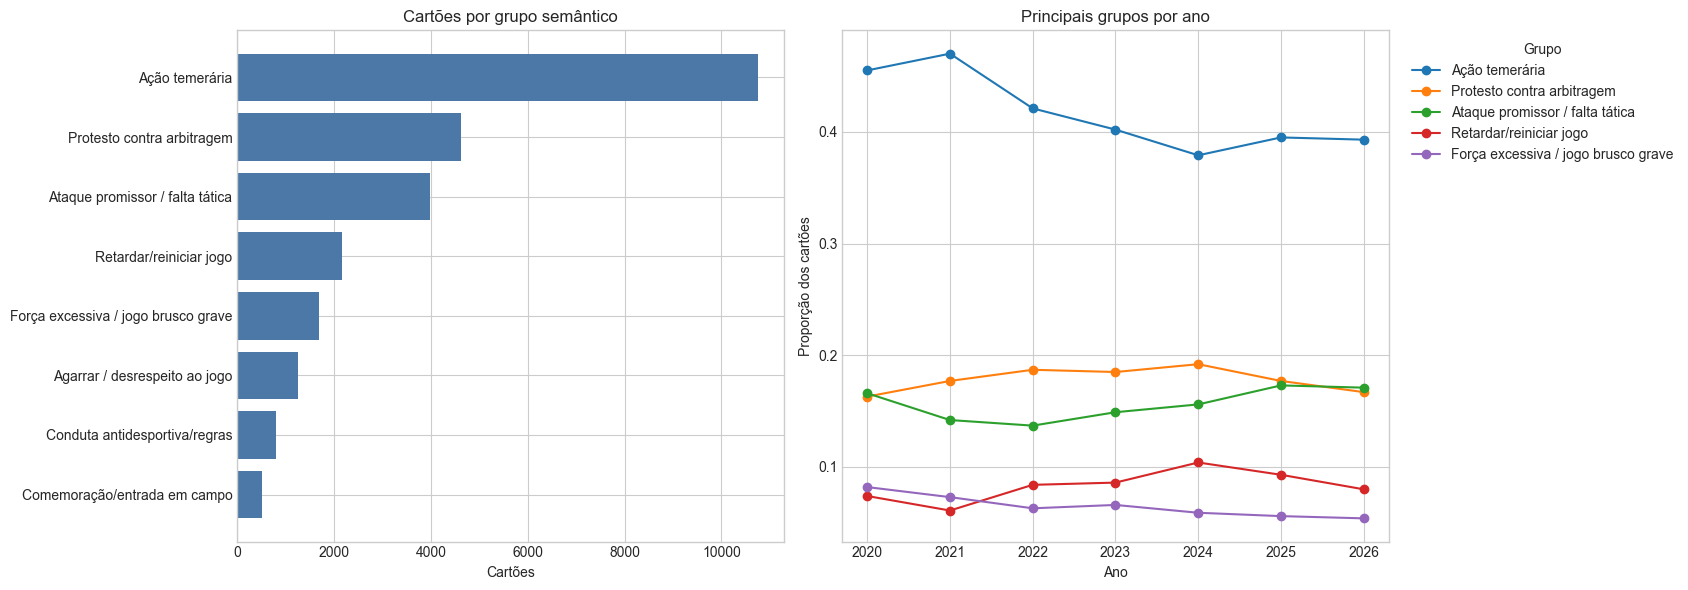

In [119]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
plot_card_summary = card_group_summary.sort_values("n_events", ascending=True)
axes[0].barh(plot_card_summary["card_reason_group"], plot_card_summary["n_events"], color="#4C78A8")
axes[0].set_title("Cartões por grupo semântico")
axes[0].set_xlabel("Cartões")
axes[0].set_ylabel("")

top_groups = card_group_summary.head(5)["card_reason_group"].tolist()
card_group_by_year[top_groups].plot(ax=axes[1], marker="o")
axes[1].set_title("Principais grupos por ano")
axes[1].set_xlabel("Ano")
axes[1].set_ylabel("Proporção dos cartões")
axes[1].legend(title="Grupo", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
save_plot(fig, "card_reason_groups_overview.png")
plt.show()

### **8.2 Por Time**

Para cada time, a tabela detalha a contagem de cada grupo semântico nos cartões recebidos. O perfil de motivos reflete o estilo de jogo: times com proporção elevada de "Ataque promissor / falta tática" tendem a ter linha defensiva mais agressiva; times com mais "Protesto contra arbitragem" apresentam comportamento mais reativo.

In [120]:
card_reason_by_team = (
    cards.groupby(["team", "card_reason_group"])
    .agg(
        n_events=("card_reason_group", "size"),
        n_yellow=("card_type", lambda values: values.eq("yellow").sum()),
        n_red=("card_type", lambda values: values.eq("red").sum()),
        n_unique_texts=(CARD_TEXT_KEY_COLUMN, "nunique"),
    )
    .reset_index()
)
team_card_totals = cards.groupby("team").size().rename("total_cards")
card_reason_by_team = card_reason_by_team.merge(team_card_totals, on="team", how="left")
card_reason_by_team["pct_team_cards"] = (card_reason_by_team["n_events"] / card_reason_by_team["total_cards"]).round(4)
card_reason_by_team = card_reason_by_team.sort_values(["total_cards", "team", "n_events"], ascending=[False, True, False])

card_reason_top_by_team = (
    card_reason_by_team.sort_values(["team", "n_events", "card_reason_group"], ascending=[True, False, True])
    .groupby("team")
    .head(1)
    .sort_values("total_cards", ascending=False)
    .reset_index(drop=True)
)
card_reason_top_by_team.head(30)

,team,card_reason_group,n_events,n_yellow,n_red,n_unique_texts,total_cards,pct_team_cards
0,Red Bull Bragantino,Ação temerária,461,460,1,146,999,0.4615
1,Fluminense,Ação temerária,413,413,0,146,991,0.4168
2,Internacional,Ação temerária,384,383,1,127,953,0.4029
3,São Paulo,Ação temerária,348,348,0,121,950,0.3663
4,Palmeiras,Ação temerária,372,372,0,120,937,0.3970
5,Corinthians,Ação temerária,423,422,1,143,936,0.4519
6,Athletico Paranaense,Ação temerária,353,353,0,124,883,0.3998
7,Atlético Mineiro,Ação temerária,321,321,0,107,877,0.3660
8,Fortaleza Esporte Clube,Ação temerária,348,348,0,115,851,0.4089
9,Flamengo,Ação temerária,408,406,2,151,834,0.4892


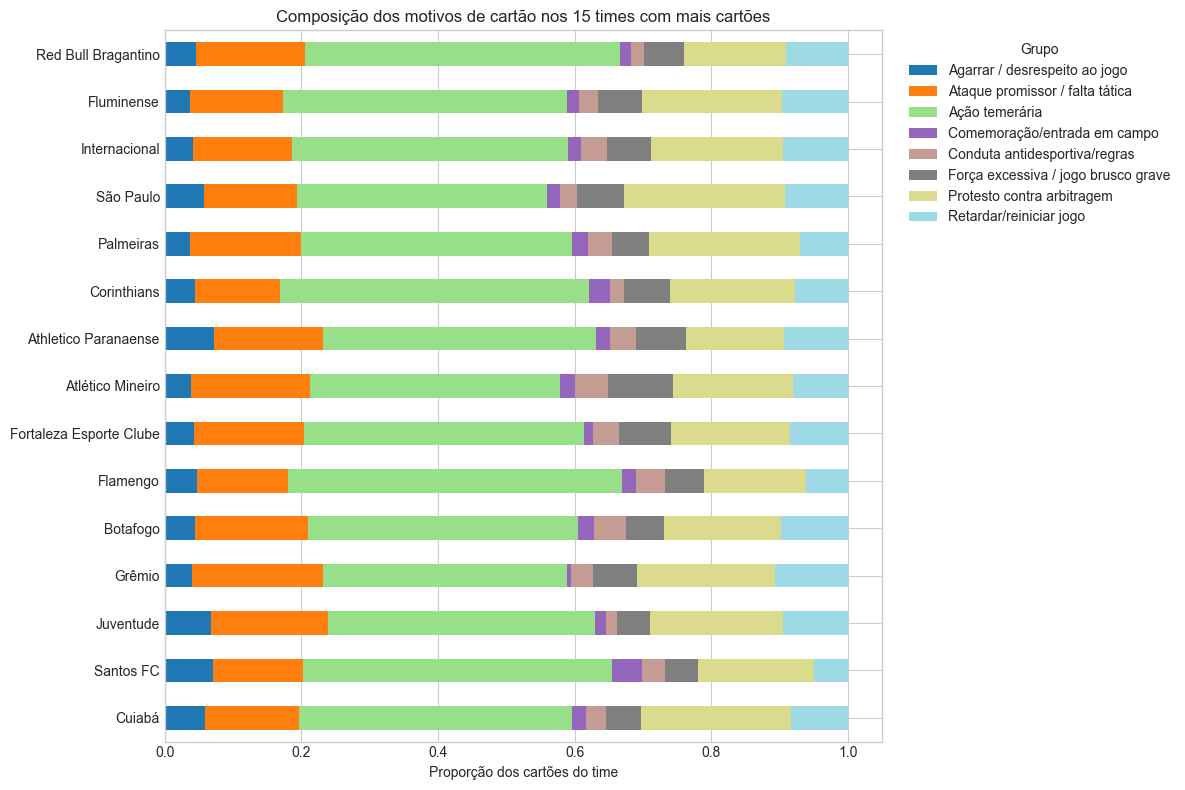

In [121]:
top_card_teams = cards["team"].value_counts().head(TOP_N_TEAMS).index
team_group_plot = pd.crosstab(
    cards.loc[cards["team"].isin(top_card_teams), "team"],
    cards.loc[cards["team"].isin(top_card_teams), "card_reason_group"],
    normalize="index",
).loc[top_card_teams]

fig, ax = plt.subplots(figsize=(12, 8))
team_group_plot.plot(kind="barh", stacked=True, ax=ax, colormap="tab20")
ax.invert_yaxis()
ax.set_title(f"Composição dos motivos de cartão nos {TOP_N_TEAMS} times com mais cartões")
ax.set_xlabel("Proporção dos cartões do time")
ax.set_ylabel("")
ax.legend(title="Grupo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
save_plot(fig, "card_reason_groups_by_team.png")
plt.show()

### **8.3 Por Árbitro**

A distribuição por árbitro mostra quais tipos de infrações são mais marcados nas partidas de cada árbitro. Árbitros com proporção elevada de "Protesto contra arbitragem" tendem a ser mais rigorosos com reclamações; árbitros com mais "Ação temerária" marcam faltas mais físicas. Esta análise alimenta o estudo de sobrevivência do notebook 3.

In [122]:
card_reason_by_referee = (
    cards.groupby(["arbitro", "card_reason_group"])
    .agg(
        n_events=("card_reason_group", "size"),
        n_yellow=("card_type", lambda values: values.eq("yellow").sum()),
        n_red=("card_type", lambda values: values.eq("red").sum()),
        n_unique_texts=(CARD_TEXT_KEY_COLUMN, "nunique"),
    )
    .reset_index()
)
referee_card_totals = cards.groupby("arbitro").size().rename("total_cards")
card_reason_by_referee = card_reason_by_referee.merge(referee_card_totals, on="arbitro", how="left")
card_reason_by_referee["pct_referee_cards"] = (card_reason_by_referee["n_events"] / card_reason_by_referee["total_cards"]).round(4)
card_reason_by_referee = card_reason_by_referee.sort_values(["total_cards", "arbitro", "n_events"], ascending=[False, True, False])

card_reason_top_by_referee = (
    card_reason_by_referee.sort_values(["arbitro", "n_events", "card_reason_group"], ascending=[True, False, True])
    .groupby("arbitro")
    .head(1)
    .sort_values("total_cards", ascending=False)
    .reset_index(drop=True)
)
card_reason_top_by_referee.head(30)

,arbitro,card_reason_group,n_events,n_yellow,n_red,n_unique_texts,total_cards,pct_referee_cards
0,Braulio da Silva Machado,Ação temerária,481,481,0,86,1178,0.4083
1,Wilton Pereira Sampaio,Ação temerária,486,484,2,145,1078,0.4508
2,Bruno Arleu de Araujo,Ação temerária,525,525,0,150,1037,0.5063
3,Ramon Abatti Abel,Ação temerária,401,400,1,148,993,0.4038
4,Flavio Rodrigues de Souza,Ação temerária,346,345,1,109,921,0.3757
5,Raphael Claus,Ação temerária,424,422,2,117,911,0.4654
6,Anderson Daronco,Ação temerária,421,419,2,133,909,0.4631
7,Felipe Fernandes de Lima,Ação temerária,325,325,0,126,847,0.3837
8,Savio Pereira Sampaio,Ação temerária,324,323,1,119,829,0.3908
9,Wagner do Nascimento Magalhaes,Ação temerária,340,339,1,107,799,0.4255


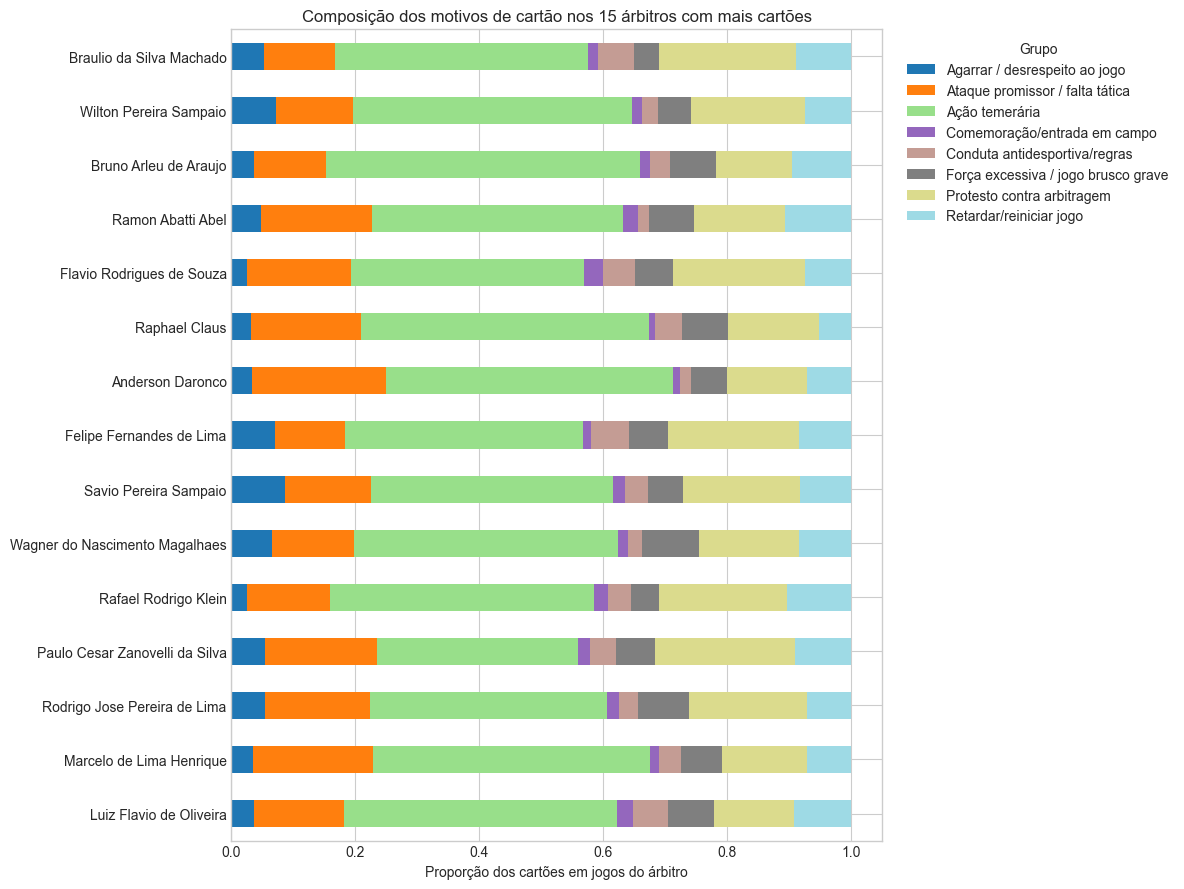

In [123]:
top_card_referees = cards["arbitro"].value_counts().head(TOP_N_REFEREES).index
referee_group_plot = pd.crosstab(
    cards.loc[cards["arbitro"].isin(top_card_referees), "arbitro"],
    cards.loc[cards["arbitro"].isin(top_card_referees), "card_reason_group"],
    normalize="index",
).loc[top_card_referees]

fig, ax = plt.subplots(figsize=(12, 9))
referee_group_plot.plot(kind="barh", stacked=True, ax=ax, colormap="tab20")
ax.invert_yaxis()
ax.set_title(f"Composição dos motivos de cartão nos {TOP_N_REFEREES} árbitros com mais cartões")
ax.set_xlabel("Proporção dos cartões em jogos do árbitro")
ax.set_ylabel("")
ax.legend(title="Grupo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
save_plot(fig, "card_reason_groups_by_referee.png")
plt.show()

### **8.4 Busca Semântica (Diagnóstico)**

Recupera os textos mais similares a uma consulta livre no espaço de embeddings fine-tunados. Útil para auditar se expressões semanticamente equivalentes ficaram no mesmo grupo e verificar a cobertura dos protótipos.

In [124]:
def embed_query(text: str) -> np.ndarray:
    return np.asarray(embedding_model.encode([ENCODE_PREFIX_QUERY + text], normalize_embeddings=True))

def semantic_search_cards(query: str, top_k: int = 10) -> pd.DataFrame:
    query_embedding = embed_query(query)
    similarities = cosine_similarity(query_embedding, card_embeddings).ravel()
    result = card_text_counts.copy()
    result["similarity"] = similarities
    return result.sort_values("similarity", ascending=False)[[
        "similarity", "n_events", "card_reason_group", "bertopic_topic", "text_for_embedding",
    ]].head(top_k)

semantic_search_cards("reclamação contra arbitragem", top_k=10)

,similarity,n_events,card_reason_group,bertopic_topic,text_for_embedding
4002,0.980283,1,Protesto contra arbitragem,5,Por reclamacao contra arbitragem.
2409,0.970312,2,Protesto contra arbitragem,5,Por reclamar contra as marcações da arbitragem
447,0.968795,7,Protesto contra arbitragem,5,Por reclamação contra a arbitragem.
955,0.966528,4,Protesto contra arbitragem,5,Reclamação contra a arbitragem.
4113,0.963529,1,Protesto contra arbitragem,5,Por reclamar de maneira ostensiva contra arbitragem.
613,0.958412,5,Protesto contra arbitragem,5,Por reclamar contra a arbitragem.
4208,0.956196,1,Protesto contra arbitragem,5,Por reclamar de forma acintosa contra a arbitragem.
4028,0.952317,1,Protesto contra arbitragem,5,Por reclamar acintosamente contra as marcações da arbitragem
434,0.944205,7,Protesto contra arbitragem,5,Reclamar de maneira ostensiva contra as marcações da arbitragem
442,0.944153,7,Protesto contra arbitragem,5,Por reclamar acintosamente contra a arbitragem.


## **9. Motivos de Acréscimos e Detecção de VAR**

Os motivos de acréscimos são tratados separadamente dos cartões. O único objetivo analítico é detectar se há menção ao VAR na justificativa de acréscimo registrada pelo árbitro.

A detecção é **léxica** — expressões regulares sobre o texto normalizado. Esta abordagem é suficiente porque a presença de VAR é um sinal fortemente textual: árbitros mencionam explicitamente "VAR", "AVAR", "revisão de vídeo" etc. quando o protocolo é ativado.

### **9.1 Exploração dos Textos de Atraso (BERTopic)**

BERTopic aplicado ao corpus de textos de atraso para mapear a diversidade temática. Esta etapa é exploratória — os clusters não são usados na detecção de VAR.

In [125]:
delay_text_counts = (
    delays[delays[DELAY_TEXT_COLUMN].ne("n/a")]
    .groupby("delay_reason_key")
    .agg(
        text_for_embedding=(DELAY_TEXT_COLUMN, "first"),
        n_games=(DELAY_TEXT_COLUMN, "size"),
        first_year=("year", "min"),
        last_year=("year", "max"),
    )
    .reset_index()
    .sort_values("n_games", ascending=False)
    .reset_index(drop=True)
)
delay_text_counts.head(25)

,delay_reason_key,text_for_embedding,n_games,first_year,last_year
0,acrescimos devido as substituicoes e atendimento medico aos atletas,Acréscimos devido as substituições e atendimento médico aos atletas.,30,2020,2026
1,acrescimos devido substituicoes e transporte de atletas lesionados,Acréscimos devido substituições e transporte de atletas lesionados.,22,2020,2021
2,acrescimos devido a substituicoes atendimento medico e retirada de atletas supostamente lesionados do campo de jogo,"Acréscimos devido a substituições, atendimento médico e retirada de atletas supostamente lesionados do campo de jogo.",14,2021,2023
3,acrescimos devido a substituicoes e atendimento de atletas supostamente lesionados,Acréscimos devido a substituições e atendimento de atletas supostamente lesionados .,13,2020,2025
4,acrescimos devido substituicoes atendimento medico aos atletas lesionados e paralisacoes diversas,"Acréscimos devido substituições, atendimento medico aos atletas lesionados e paralisações diversas.",13,2021,2025
5,acrescimos devido as substituicoes atendimento medico aos atletas e checagem do var,"Acréscimos devido as substituições, atendimento médico aos atletas e checagem do var.",12,2020,2022
6,nao houve atraso no inicio e reinicio de jogo acrescimos motivados por substituicoes e atendimento a jogadores supostamente lesionados,-nao houve atraso no inicio e reinicio de jogo.-acrescimos motivados por substituições e atendimento a jogadores supostamente lesionados.,11,2021,2025
7,acrescimos devido substituicoes atendimento medico aos atletas lesionados checagens do var e paralisacoes diversas,"Acréscimos devido substituições, atendimento medico aos atletas lesionados, checagens do var e paralisações diversas.",11,2023,2024
8,acrescimos devido substituicoes atendimento medico aos atletas lesionados e checagens do var,"Acréscimos devido substituições, atendimento medico aos atletas lesionados e checagens do var.",11,2020,2022
9,acrescimos devido paralisacoes substituicoes e atendimento de atletas supostamente lesionados,"Acréscimos devido paralisações, substituições e atendimento de atletas supostamente lesionados.",10,2020,2024


In [126]:
delay_texts = delay_text_counts["text_for_embedding"].tolist()
delay_embeddings = base_model.encode(
    [ENCODE_PREFIX_PASSAGE + t for t in delay_texts],
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
delay_embeddings = np.asarray(delay_embeddings)
print(f"Embeddings de atrasos/acréscimos: {delay_embeddings.shape}")

Batches: 100%|██████████| 59/59 [00:14<00:00,  4.11it/s]

Embeddings de atrasos/acréscimos: (3764, 768)


In [127]:
delay_topic_model = make_topic_model(DELAY_MIN_TOPIC_SIZE)
delay_topics, _ = delay_topic_model.fit_transform(delay_texts, embeddings=delay_embeddings)
delay_text_counts["bertopic_topic"] = delay_topics

delay_text_counts_for_summary = delay_text_counts.rename(columns={"n_games": "n_events"})
delay_topic_summary = build_topic_summary(delay_topic_model, delay_text_counts_for_summary, "bertopic_topic")
delay_topic_summary.head(20)

,bertopic_topic,Count,Name,Representation,Representative_Docs,n_unique_texts,n_events,top_terms
0,0,681,0_atraso_entrada_informo_equipes,"[atraso, entrada, informo, equipes, reinício, acréscimos, substituições, segundo, atendimento, ambas]","[Houve 3 minutos de atraso no início da partida, devido a equipe saf botafogo se apresentar com 3 minutos de atraso para entrada em campo e a equipe do são paulo f.c atrasar 5 minutos para a entrada em campo. houve 3...",681,924,"atraso, entrada, informo, equipes, reinício, acréscimos, substituições, segundo"
1,1,569,1_covid_covid 19_19_homenagem,"[covid, covid 19, 19, homenagem, silêncio, respeitado, vitimas, vitimas covid, vitimas covid 19, silêncio homenagem]","[Foi respeitado 1 minuto de silêncio em homenagem póstuma as vítimas do covid-19. acréscimos por substituições, entrada da maca para retirada de jogadores do campo, reposição do tempo perdido e tempo de var., Foi res...",569,896,"covid, covid 19, 19, homenagem, silêncio, respeitado, vitimas, vitimas covid"
2,-1,438,-1_substituições_homenagem_acréscimos_houve,"[substituições, homenagem, acréscimos, houve, silêncio, atletas, respeitado, atendimento, não houve, não]",[Não houve atraso no inicio e no reinicio do jogo.acréscimos de 2 minutos no 1° tempo e de 5 minutos no 2° tempo por atendimento aos atletas supostamente lesionados e substituições.informo que foi realizado 1 minuto ...,438,671,outliers
3,2,427,2_homenagem_póstuma_homenagem póstuma_respeitado,"[homenagem, póstuma, homenagem póstuma, respeitado, silêncio, silêncio homenagem, torcedor, silêncio homenagem póstuma, substituições, acréscimos]","[Acréscimos motivados por substituições, atendimento e retirada de atletas supostamente lesionados. foi respeitado 1 minuto de silêncio em homenagem póstuma ao sr. silvio da silva e sr. renato cesar bastos, torcedore...",427,554,"homenagem, póstuma, homenagem póstuma, respeitado, silêncio, silêncio homenagem, torcedor, silêncio homenagem póstuma"
4,3,310,3_lesionados_acréscimos_atletas_substituições,"[lesionados, acréscimos, atletas, substituições, supostamente, supostamente lesionados, lesionados acréscimos, atendimento, atletas supostamente, atletas supostamente lesionados]","[Acréscimos para substituições e atendimento a atletas supostamente lesionados., Acréscimos devido as substituições e atendimento de atletas supostamente lesionados., Acréscimos devido substituições e atendimento de ...",310,546,"lesionados, acréscimos, atletas, substituições, supostamente, supostamente lesionados, lesionados acréscimos, atendimento"
5,4,275,4_primeiro_segundo_primeiro segundo_substituições,"[primeiro, segundo, primeiro segundo, substituições, segundo substituições, lesionados, atletas, atendimento, acréscimos primeiro, segundo paralisações]","[Acréscimos de 1 minuto no primeiro tempo e 6 minutos no segundo tempo devido à paralisações, substituições e atendimento a atletas lesionados., Acréscimos de 3 minutos no primeiro tempo, e 6 minutos no segundo tempo...",275,397,"primeiro, segundo, primeiro segundo, substituições, segundo substituições, lesionados, atletas, atendimento"
6,5,176,5_não_não houve_houve_atrasos acréscimos,"[não, não houve, houve, atrasos acréscimos, atrasos, houve atrasos acréscimos, houve atraso acréscimos, não houve atrasos, houve atrasos, atraso acréscimos]","[Não houve atrasos. acréscimos devido as substituições, entrada da maca em campo para retirada de atletas supostamente lesionados e reposição de bola., Não houve atrasos. acréscimos devido as substituições, retirada ...",176,260,"não, não houve, houve, atrasos acréscimos, atrasos, houve atrasos acréscimos, houve atraso acréscimos, não houve atrasos"
7,6,157,6_gols_comemoração_substituições_comemorações,"[gols, comemoração, substituições, comemorações, acréscimos, comemoração gols, gol, comemorações gols, atletas, retirada]","[Acréscimos devido atendimento médico a atletas supostamente lesionados, substituições e comemoração de gols., Acréscimos devido a atendimento mé

In [128]:
delay_topic_examples = top_examples_by_topic(
    delay_text_counts.rename(columns={"n_games": "n_events"}),
    "bertopic_topic",
    top_n=5,
).rename(columns={"n_events": "n_games"})
delay_topic_examples.head(30)

,bertopic_topic,n_games,text_for_embedding
0,-1,10,"Acréscimos devido a substituições, atendimento médico e checagens do árbitro de vídeo."
1,-1,9,ACRÉSCIMOS DEVIDO A SUBSTITUIÇÕES E ATENDIMENTO MÉDICO AOS ATLETAS SUPOSTAMENTE LESIONADOS.
2,-1,7,"Acréscimos devido a substituições, atendimento médico e checagem do árbitro de vídeo."
3,-1,4,"Acréscimos motivados em recuperar o tempo perdido com substituições, reposições de bola em jogo e atendimentos medico aos atletas supostamente lesionados."
4,-1,4,"Acréscimo devido as substituições, atendimento médico aos atletas, e checagem do var."
5,0,11,-nao houve atraso no inicio e reinicio de jogo.-acrescimos motivados por substituições e atendimento a jogadores supostamente lesionados.
6,0,3,-nao houve atraso no inicio e reinicio de jogo-acrescimos motivados por atendimento medico a jogadores supostamente lesionados e substituições.
7,0,3,-nao houve atraso no inicio e reinicio de jogo-acrescimos motivados por substituições e atendimento a jogadores lesionados
8,0,2,"Acréscimos devido a substiuições, atendimento médico e retirada de jogadores do campo de jogo pela maca.informo que houve atraso no reinicio de jogo (segundo tempo) de 3 minutos em virtude do atraso de 4 minutos para..."
9,0,2,"Acréscimos em função de avaliação de lesão de jogadores, substituições e perda de tempo em reposições de bola em jogo. o segundo tempo de partida começou com 02 minutos de atraso, devido ao atraso de 02 minutos da eq..."


### **9.2 Detecção Léxica de VAR**

Os padrões cobrem siglas institucionais (`VAR`, `AVAR`, `VOR`, `ARA`), variações descritivas (`árbitro de vídeo`), termos de processo (`checagem`, `revisão`, `review`) e referências a infraestrutura (`monitor`, `cabine`). O sinal `monitor_cabine` é o mais ambíguo — "monitor" pode aparecer em contextos não-VAR.

In [129]:
VAR_SIGNAL_PATTERNS = {
    "var": r"\bvar\b",
    "avar": r"\bavar\b",
    "vor": r"\bvor\b|sala\s+vor",
    "ara": r"\bara\b",
    "arbitro_de_video": r"arbitro\s+de\s+video|arbitragem\s+de\s+video|video\s+arbitro",
    "checagem": r"checag(?:em|ens)|checando|checar",
    "revisao": r"revis(?:ao|oes|ar|ado|ada)|review",
    "monitor_cabine": r"\bmonitor\b|\bcabine\b",
}

def detect_var_signals(text: str) -> tuple[bool, str]:
    normalized = normalize_text(text)
    matches = [name for name, pattern in VAR_SIGNAL_PATTERNS.items() if re.search(pattern, normalized)]
    return bool(matches), ", ".join(matches)

var_detection = delays[DELAY_TEXT_COLUMN].apply(detect_var_signals)
delays["var_used"] = var_detection.map(lambda item: item[0])
delays["var_signal"] = var_detection.map(lambda item: item[1])

var_summary = pd.Series({
    "games_total": len(delays),
    "games_with_var_signal": int(delays["var_used"].sum()),
    "pct_with_var_signal": round(delays["var_used"].mean(), 4),
})
var_summary

games_total              5663.0000
games_with_var_signal    2031.0000
pct_with_var_signal         0.3586
dtype: float64

In [130]:
signal_counts = {}
for signal_name, pattern in VAR_SIGNAL_PATTERNS.items():
    signal_counts[signal_name] = delays[DELAY_TEXT_COLUMN].apply(
        lambda t, p=pattern: bool(re.search(p, normalize_text(str(t))))
    ).sum()

signal_dist = pd.Series(signal_counts, name='partidas').sort_values(ascending=False)
print('Frequência de cada sinal VAR:')
print(signal_dist.to_string())

only_monitor = (
    delays[delays['var_signal'].eq('monitor_cabine')]
    [[DELAY_TEXT_COLUMN, 'year']]
    .drop_duplicates(DELAY_TEXT_COLUMN)
    .sort_values('year')
    .reset_index(drop=True)
)
print(f'\nTextos ativados exclusivamente por monitor_cabine: {len(only_monitor)}')
print('Revisar manualmente para estimar precisão do detector neste sinal.')
only_monitor.head(15)

Frequência de cada sinal VAR:
var                 1745
checagem            1512
revisao              561
ara                  136
arbitro_de_video      79
vor                   48
monitor_cabine        36
avar                   2

Textos ativados exclusivamente por monitor_cabine: 1
Revisar manualmente para estimar precisão do detector neste sinal.


,delay_reason_clean,year
0,"Não houve atraso. os acréscimos foram dados por reposição da bola em jogo, gols, substituições atendimento ao goleiro mandante, tempo de cabine e retirada de atletas para atendimento.",2023


### **9.3 Evolução do VAR por Ano**

Proporção de partidas com sinal de VAR detectado por ano. Espera-se crescimento após a implementação do sistema no Campeonato Brasileiro a partir de 2019.

In [131]:
delay_var_by_year = (
    delays.groupby("year")
    .agg(
        games=("game_id", "count"),
        games_with_var_signal=("var_used", "sum"),
    )
    .reset_index()
)
delay_var_by_year["pct_with_var_signal"] = (
    delay_var_by_year["games_with_var_signal"] / delay_var_by_year["games"]
).round(4)
delay_var_by_year

,year,games,games_with_var_signal,pct_with_var_signal
0,2020,880,211,0.2398
1,2021,882,375,0.4252
2,2022,882,340,0.3855
3,2023,882,347,0.3934
4,2024,882,325,0.3685
5,2025,882,326,0.3696
6,2026,373,107,0.2869


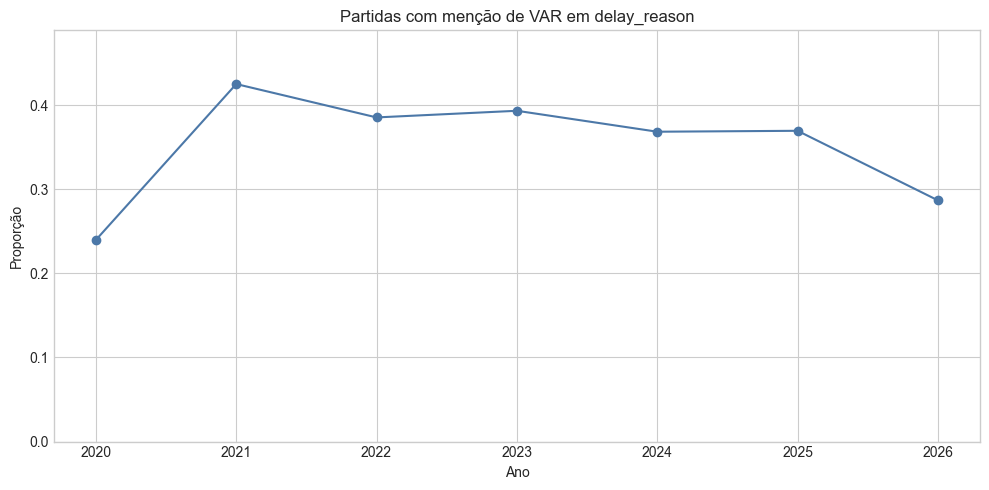

In [132]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(delay_var_by_year["year"], delay_var_by_year["pct_with_var_signal"], marker="o", color="#4C78A8")
ax.set_title("Partidas com menção de VAR em delay_reason")
ax.set_xlabel("Ano")
ax.set_ylabel("Proporção")
ax.set_ylim(0, max(0.05, delay_var_by_year["pct_with_var_signal"].max() * 1.15))
plt.tight_layout()
save_plot(fig, "var_mentions_by_year.png")
plt.show()

In [133]:
var_examples = (
    delays[delays["var_used"]]
    .sort_values(["year", "round", "game_number"])
    [["year", "round", "home_team", "away_team", "arbitro", "var_signal", DELAY_TEXT_COLUMN]]
    .head(25)
)
var_examples

,year,round,home_team,away_team,arbitro,var_signal,delay_reason_clean
10,2020,1,Santos FC,Red Bull Bragantino,Ricardo Marques Ribeiro,"var, checagem",Não houve atraso no inicio e reinicio do jogo. foi cumprido a diretriz técnica operacional da cbf de entrada das equipes 05 (cinco) minutos antes do jogo para equipe local (15:55) e 04 (quatro) minutos antes do jogo ...
19,2020,1,Sport Recife,Ceará,Edina Alves Batista,"var, checagem","Não houve atraso. Foi cumprido a Diretriz Técnica Operacional da CBF de entrada das equipes , 5 (cinco) minutos antes do jogo para equipe local (20:55) e 4 (quatro) minutos antes do jogo para equipe visitante (20:56)..."
25,2020,1,Fortaleza Esporte Clube,Athletico Paranaense,Braulio da Silva Machado,"var, checagem","Não houve atraso no início e reinício de jogo. Foi cumprido a Diretriz Técnica Operacional da CBF de entrada das equipes , 5 (cinco) minutos antes do jogo para equipe local (18:55) e 4 (quatro) minutos antes do jogo ..."
74,2020,2,Vasco da Gama,Sport Recife,Rodolpho Toski Marques,"var, revisao","Não houve atraso no início e reinício de jogo.foram acrescidos 2 minutos no primeiro tempo e 8 minutos no segundo tempo devido as substituições, reposição de bola em jogo, avaliação médica dos atletas supostamente le..."
83,2020,2,Atlético Mineiro,Corinthians,Wagner do Nascimento Magalhaes,var,"Não houve atraso no início e reinício da partida.acréscimos devido substituições,atendimento à atletas supostamente lesionados,reposição de bola em jogo e var.houve 01 minuto de silêncio em homenagem às vitimas do co..."
92,2020,2,Athletico Paranaense,Goiás,Diego Pombo Lopez,"var, checagem","Acréscimos no primeiro tempo devido a atendimento e retirada pela ambulância do atleta número 55 do athlético e também por checagens do var. acréscimos no segundo tempo devido a substituições, retirada de atletas sup..."
98,2020,2,Atlético,Flamengo,Luiz Flavio de Oliveira,"var, checagem","Não houve atrasos.acréscimos motivados por, atendimento médico, substituições, reposição de bola em jogo e checagem do var.informo que na relação nominal de atletas da equipe atletico cg, constava que o uniforme do g..."
120,2020,3,Fluminense,Internacional,Raphael Claus,"var, revisao","Não houve atraso no início e reinício da partida. houve acréscimos no primeiro e no segundo tempo de partida, devido as substituições, revisões do var, reposições de bola em jogo e atendimentos aos atletas supostamen..."
126,2020,3,Santos FC,Athletico Paranaense,Anderson Daronco,"var, checagem","Acréscimos de 4 minutos no primeiro tempo e 5 minutos no segundo tempo devido à paralisações, substituições, atendimento a atletas lesionados e checagem do var."
132,2020,3,Esporte Clube Bahia,Red Bull Bragantino,Felipe Fernandes de Lima,"var, checagem","Acréscimos devido as paralisações para retirada de atletas supostamente lesionados do campo de jogo, substituições e recuperação de tempo perdido por checagem do var.informo que foi respeitado um minuto de silêncio e..."


### **9.4 VAR por Time e Árbitro**

Para times: contagem sobre partidas em que o time aparece como mandante ou visitante — o mesmo jogo é contado para ambos. Para árbitros: contagem sobre as partidas apitadas. Em ambos os casos, `var_used` indica presença de sinal textual de VAR no campo de atraso, não validação externa do protocolo.

In [134]:
def most_common_non_empty(values: pd.Series) -> str:
    cleaned = values.astype(str).str.strip()
    cleaned = cleaned[cleaned.ne("")]
    if cleaned.empty:
        return ""
    return cleaned.value_counts().idxmax()

delay_home_games = delays.rename(columns={"home_team": "team", "away_team": "opponent"})[
    ["year", "round", "game_id", "game_number", "team", "opponent", "arbitro", "var_used", "var_signal", DELAY_TEXT_COLUMN]
]
delay_away_games = delays.rename(columns={"away_team": "team", "home_team": "opponent"})[
    ["year", "round", "game_id", "game_number", "team", "opponent", "arbitro", "var_used", "var_signal", DELAY_TEXT_COLUMN]
]
delay_team_games = pd.concat([delay_home_games, delay_away_games], ignore_index=True)

delay_var_by_team = (
    delay_team_games.groupby("team")
    .agg(
        games=("game_id", "count"),
        games_with_var_signal=("var_used", "sum"),
        top_var_signal=("var_signal", most_common_non_empty),
    )
    .reset_index()
)
delay_var_by_team["pct_with_var_signal"] = (
    delay_var_by_team["games_with_var_signal"] / delay_var_by_team["games"]
).round(4)
delay_var_by_team = delay_var_by_team.sort_values(["games", "games_with_var_signal"], ascending=False).reset_index(drop=True)
delay_var_by_team.head(30)

,team,games,games_with_var_signal,top_var_signal,pct_with_var_signal
0,Red Bull Bragantino,456,174,"var, checagem",0.3816
1,Flamengo,443,189,"var, checagem",0.4266
2,Corinthians,442,194,"var, checagem",0.4389
3,Fluminense,442,173,"var, checagem",0.3914
4,Palmeiras,426,196,"var, checagem",0.4601
5,Internacional,417,177,"var, checagem",0.4245
6,Athletico Paranaense,398,170,"var, checagem",0.4271
7,São Paulo,396,207,"var, checagem",0.5227
8,Atlético Mineiro,396,146,"var, checagem",0.3687
9,Fortaleza Esporte Clube,368,158,"var, checagem",0.4293


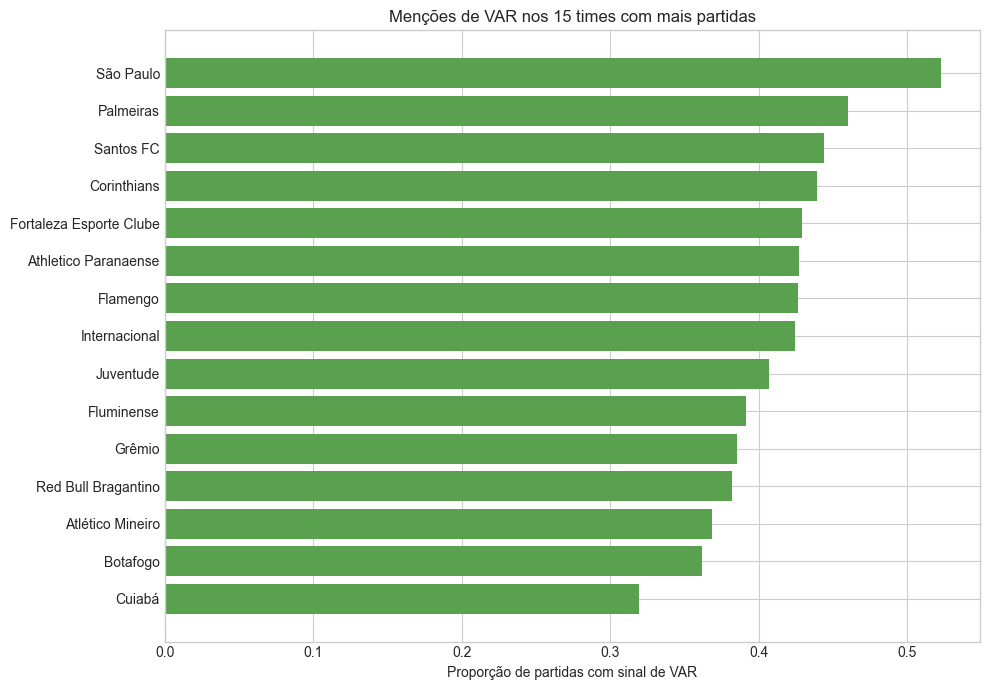

In [135]:
top_var_teams = delay_var_by_team.head(TOP_N_TEAMS).sort_values("pct_with_var_signal")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_var_teams["team"], top_var_teams["pct_with_var_signal"], color="#59A14F")
ax.set_title(f"Menções de VAR nos {TOP_N_TEAMS} times com mais partidas")
ax.set_xlabel("Proporção de partidas com sinal de VAR")
ax.set_ylabel("")
plt.tight_layout()
save_plot(fig, "var_mentions_by_team.png")
plt.show()

In [136]:
delay_var_by_referee = (
    delays.groupby("arbitro")
    .agg(
        games=("game_id", "count"),
        games_with_var_signal=("var_used", "sum"),
        top_var_signal=("var_signal", most_common_non_empty),
    )
    .reset_index()
)
delay_var_by_referee["pct_with_var_signal"] = (
    delay_var_by_referee["games_with_var_signal"] / delay_var_by_referee["games"]
).round(4)
delay_var_by_referee = delay_var_by_referee.sort_values(["games", "games_with_var_signal"], ascending=False).reset_index(drop=True)
delay_var_by_referee.head(30)

,arbitro,games,games_with_var_signal,top_var_signal,pct_with_var_signal
0,Anderson Daronco,255,83,"var, checagem",0.3255
1,Raphael Claus,243,80,"var, checagem",0.3292
2,Ramon Abatti Abel,233,102,"var, checagem",0.4378
3,Wilton Pereira Sampaio,223,103,"var, checagem",0.4619
4,Braulio da Silva Machado,222,131,"var, checagem",0.5901
5,Flavio Rodrigues de Souza,217,94,"var, checagem",0.4332
6,Bruno Arleu de Araujo,205,87,"var, checagem",0.4244
7,Savio Pereira Sampaio,190,80,"var, checagem",0.4211
8,Marcelo de Lima Henrique,175,67,"var, checagem",0.3829
9,Wagner do Nascimento Magalhaes,165,59,"var, checagem",0.3576


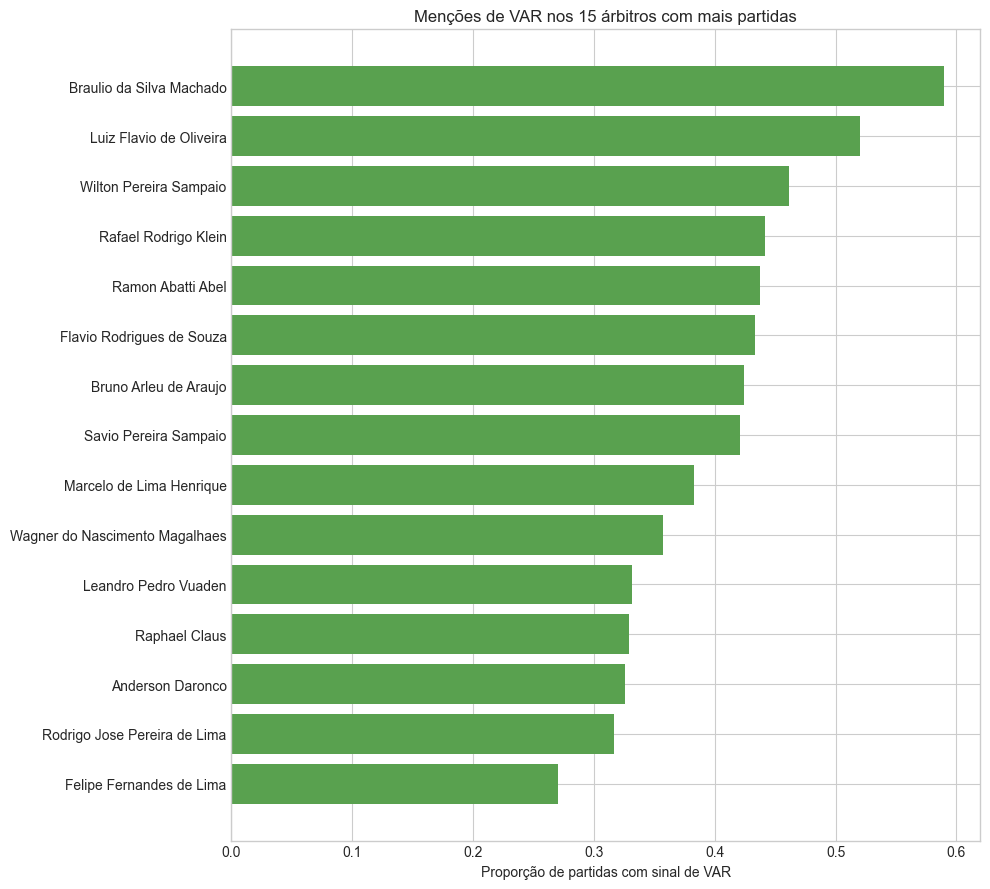

In [137]:
top_var_referees = delay_var_by_referee.head(TOP_N_REFEREES).sort_values("pct_with_var_signal")
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(top_var_referees["arbitro"], top_var_referees["pct_with_var_signal"], color="#59A14F")
ax.set_title(f"Menções de VAR nos {TOP_N_REFEREES} árbitros com mais partidas")
ax.set_xlabel("Proporção de partidas com sinal de VAR")
ax.set_ylabel("")
plt.tight_layout()
save_plot(fig, "var_mentions_by_referee.png")
plt.show()

## **10. Salvamento dos Artefatos**

Arquivos gerados em `data/processed/semantic_reasons/card_reasons/`:

- `card_reasons_with_labels.csv` — dataset completo com grupo semântico por cartão
- `card_reason_group_summary.csv` — distribuição de eventos por grupo
- `card_reason_by_team.csv` / `card_reason_by_referee.csv` — tabelas analíticas
- `card_reason_outros_audit.csv` — textos não atribuídos (diagnóstico; vazio se cobertura total)

Visualizações em `viz/`.

In [138]:
outros_audit = (
    cards[cards["card_reason_group"].eq("Outros")]
    .groupby(CARD_TEXT_COLUMN)
    .size()
    .reset_index(name="n_events")
    .sort_values("n_events", ascending=False)
)

card_topic_summary_path = CARD_OUTPUT_DIR / "card_bertopic_topic_summary.csv"
card_topic_examples_path = CARD_OUTPUT_DIR / "card_bertopic_topic_examples.csv"
card_unique_topics_path = CARD_OUTPUT_DIR / "card_reason_unique_topics_labels.csv"
card_labeled_path = CARD_OUTPUT_DIR / "card_reasons_with_labels.csv"
card_group_summary_path = CARD_OUTPUT_DIR / "card_reason_group_summary.csv"
card_group_by_year_path = CARD_OUTPUT_DIR / "card_reason_group_by_year.csv"
card_group_by_type_path = CARD_OUTPUT_DIR / "card_reason_group_by_card_type.csv"
card_reason_by_team_path = CARD_OUTPUT_DIR / "card_reason_by_team.csv"
card_reason_top_by_team_path = CARD_OUTPUT_DIR / "card_reason_top_by_team.csv"
card_reason_by_referee_path = CARD_OUTPUT_DIR / "card_reason_by_referee.csv"
card_reason_top_by_referee_path = CARD_OUTPUT_DIR / "card_reason_top_by_referee.csv"
outros_audit_path = CARD_OUTPUT_DIR / "card_reason_outros_audit.csv"

delay_topic_summary_path = DELAY_OUTPUT_DIR / "delay_bertopic_topic_summary.csv"
delay_topic_examples_path = DELAY_OUTPUT_DIR / "delay_bertopic_topic_examples.csv"
delay_unique_topics_path = DELAY_OUTPUT_DIR / "delay_reason_unique_topics.csv"
delay_labeled_path = DELAY_OUTPUT_DIR / "delay_reasons_with_var.csv"
delay_var_by_year_path = DELAY_OUTPUT_DIR / "delay_var_by_year.csv"
delay_var_by_team_path = DELAY_OUTPUT_DIR / "delay_var_by_team.csv"
delay_var_by_referee_path = DELAY_OUTPUT_DIR / "delay_var_by_referee.csv"

card_topic_summary.to_csv(card_topic_summary_path, index=False)
card_topic_examples.to_csv(card_topic_examples_path, index=False)
card_text_counts.to_csv(card_unique_topics_path, index=False)
cards.to_csv(card_labeled_path, index=False)
card_group_summary.to_csv(card_group_summary_path, index=False)
card_group_by_year.to_csv(card_group_by_year_path)
card_group_by_type.to_csv(card_group_by_type_path)
card_reason_by_team.to_csv(card_reason_by_team_path, index=False)
card_reason_top_by_team.to_csv(card_reason_top_by_team_path, index=False)
card_reason_by_referee.to_csv(card_reason_by_referee_path, index=False)
card_reason_top_by_referee.to_csv(card_reason_top_by_referee_path, index=False)
outros_audit.to_csv(outros_audit_path, index=False)

delay_topic_summary.to_csv(delay_topic_summary_path, index=False)
delay_topic_examples.to_csv(delay_topic_examples_path, index=False)
delay_text_counts.to_csv(delay_unique_topics_path, index=False)
delays.to_csv(delay_labeled_path, index=False)
delay_var_by_year.to_csv(delay_var_by_year_path, index=False)
delay_var_by_team.to_csv(delay_var_by_team_path, index=False)
delay_var_by_referee.to_csv(delay_var_by_referee_path, index=False)

output_paths = [
    card_topic_summary_path,
    card_topic_examples_path,
    card_unique_topics_path,
    card_labeled_path,
    card_group_summary_path,
    card_group_by_year_path,
    card_group_by_type_path,
    card_reason_by_team_path,
    card_reason_top_by_team_path,
    card_reason_by_referee_path,
    card_reason_top_by_referee_path,
    outros_audit_path,
    delay_topic_summary_path,
    delay_topic_examples_path,
    delay_unique_topics_path,
    delay_labeled_path,
    delay_var_by_year_path,
    delay_var_by_team_path,
    delay_var_by_referee_path,
]

print("Arquivos salvos:")
for output_path in output_paths:
    print(f"  {output_path}")

Arquivos salvos:
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_bertopic_topic_summary.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_bertopic_topic_examples.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_unique_topics_labels.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reasons_with_labels.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_group_summary.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_group_by_year.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_group_by_card_type.csv
  /Users/gcarninatto/D